# StockEye v4.1 — Detección de espacios vacíos en góndolas de supermercado (local)

El modelo final detecta **2 clases**:

| id | Clase | Significado |
|---|---|---|
| 0 | `gondola` | el mueble completo (estantería, refrigerador, isla) |
| 1 | `vacio` | cada **espacio vacío** de repisa (quiebre de stock) |

Los **productos** se detectan automáticamente solo como **ayuda** (sugerir góndolas y huecos, capa guía gris
en el editor). No se entrenan, así revisas solo góndolas y vacíos (~1 min por foto). Si algún día quieres
también la clase producto, pon `INCLUIR_PRODUCTO = True` en la celda 2.

**% de quiebre por góndola** = área de vacíos dentro de la góndola / área de la góndola.

## ¿Qué cambia respecto a v2 y v3?

| | v2 (Colab) | v3 (local rápida) | **v4 (local, calidad)** |
|---|---|---|---|
| Productos (ayuda) | GDINO base + SAM + maestro HITL | 1 YOLO de góndolas | **Ensemble**: YOLO góndolas + maestro HITL de Colab (+ GDINO opcional) con *Weighted Boxes Fusion* |
| Góndola | GDINO+SAM → YOLO góndola (marcaba la foto entera) | no | **grupos de productos vecinos** → una caja por mueble |
| Vacíos sugeridos | geometría + textura | geometría + textura | `empty` de foduu + huecos **entre productos vecinos**, sin reglas que fallan en fotos de pasillo |
| Revisión humana | no | no | **editor de cajas en el notebook** (manual y automático por clase) |
| Entrenamiento | 4 modelos YOLO11 | 1 modelo | **maestro → alumno** sobre **YOLO26** |
| Validación | etiquetas automáticas | etiquetas automáticas | **etiquetas revisadas por ti** (métricas reales) |

## Flujo

1. Preparar fotos y separar train/val sin fugas (celdas 1–4).
2. Ver las etiquetas que hiciste en Colab (celda 5).
3. **Etiquetado automático** con varias fuentes y su fusión (celdas 6–11).
4. **Galería** para ver todas las fotos y sus cajas (celdas 12–14).
5. **Editor**: marcar góndolas y vacíos a mano o aceptar sugerencias automáticas (celdas 15–17).
6. **Aprendizaje activo**: maestro con tus fotos revisadas → te propone vacíos en el resto → modelo final (celdas 18–21).
7. Evaluación honesta y análisis de quiebres por góndola (celdas 22–25).

> Cada celda de código está **numerada** (`# [Celda N]`) y tiene arriba su explicación.
> Para comprobar que todo funciona rápido, pon `MODO_PRUEBA = True` en la celda 2.

## 1. Entorno, configuración y fotos

### Celda 1 · Instalación de dependencias

- **Qué hace:** Instala solo las librerías que falten en el kernel actual (PyTorch CPU si no hay GPU NVIDIA, Ultralytics, anywidget para el editor, etc.).
- **Qué necesita:** El kernel **Python (StockEye .venv)** seleccionado arriba a la derecha.
- **Qué deja listo:** Todas las librerías importables.
- **Tiempo y recursos:** La primera vez unos minutos (descargas); después termina al instante.
- **Qué revisar:** Que imprima `Dependencias listas ✅`. Si instaló algo nuevo, reinicia el kernel.

In [1]:
# [Celda 1] Instalación de dependencias
import sys, shutil, subprocess, importlib.util

def instalar(*paquetes):
    # Usa el pip del mismo Python que ejecuta el notebook
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *paquetes])

if sys.prefix == sys.base_prefix:
    print("⚠️  El kernel no está en un entorno virtual; elige 'Python (StockEye .venv)'.")

# PyTorch: versión CPU si no hay GPU NVIDIA (mucho más liviana)
if importlib.util.find_spec("torch") is None:
    if shutil.which("nvidia-smi"):
        instalar("torch", "torchvision")
    else:
        instalar("torch", "torchvision", "--index-url", "https://download.pytorch.org/whl/cpu")

# {nombre al importar: nombre en pip}
LIBRERIAS = {
    "ultralytics": "ultralytics>=8.4.0",      # 8.4+ trae YOLO26
    "anywidget": "anywidget",                  # editor de cajas interactivo
    "ipywidgets": "ipywidgets",
    "huggingface_hub": "huggingface_hub",
    "transformers": "transformers>=4.40",      # solo para Grounding DINO (opcional)
    "cv2": "opencv-python",
    "PIL": "pillow",
    "matplotlib": "matplotlib",
    "pandas": "pandas",
    "yaml": "pyyaml",
}
faltan = [pip for mod, pip in LIBRERIAS.items() if importlib.util.find_spec(mod) is None]
if faltan:
    print("Instalando:", ", ".join(faltan))
    instalar(*faltan)
    print("Se instalaron paquetes nuevos: reinicia el kernel y continúa desde la celda 2.")
print("Dependencias listas ✅")

Dependencias listas ✅


### Celda 2 · Configuración global

- **Qué hace:** Importa librerías y define rutas, clases, perfil de entrenamiento y todos los parámetros.
- **Qué necesita:** Celda 1.
- **Qué deja listo:** `CFG`, rutas (`WORK`, `FOTOS_DIR`, …), `CLASES`, `DEVICE` y `MODO_ETIQUETADO`.
- **Tiempo y recursos:** Instantáneo.
- **Qué revisar:** Que el perfil, el dispositivo y la RAM libre impresos sean razonables.

**Perillas principales**

| Variable | Opciones | Efecto |
|---|---|---|
| `MODO_ETIQUETADO` | `"mixto"` (recomendado) · `"manual"` · `"automatico"` | cómo abre el editor cada foto: con cajas automáticas para corregir, vacía para dibujar todo, o sin editor |
| `PERFIL` | `"rapido"` · `"equilibrado"` · `"calidad"` | modelo YOLO26 y resolución de entrenamiento |
| `RONDAS` | `1` o `2` | 2 = entrena un maestro, re-etiqueta y entrena el modelo final |
| `MODO_PRUEBA` | `True` / `False` | corrida corta (12 fotos, 2 épocas) para comprobar que todo funciona |
| `MODO_FRESCO` | `True` (por defecto) / `False` | usa solo `HILOS_FRESCO` hilos (4 de 8): la CPU trabaja ~50 % y se calienta menos; entrena ~1.5–2× más lento |
| `TEMP_PAUSA` / `TEMP_REANUDAR` | °C (85 / 70) | **protección térmica**: si la CPU llega a 85 °C se pausa todo hasta que baje de 70 °C |

> Tu Ryzen 5 3400G trabaja hasta 95 °C y se protege solo, pero con pasta térmica vieja conviene ir con margen.
> Los tiempos de la tabla de perfiles son con todos los hilos; con `MODO_FRESCO` cuenta aprox. el doble.

| Perfil | Modelo | Tamaño | Épocas maestro / final | Tiempo aprox. en tu CPU |
|---|---|---|---|---|
| `rapido` | YOLO26n | 640 | 20 / 40 | ~1 min por época |
| `equilibrado` | YOLO26s | 640 | 25 / 50 | ~2–3 min por época |
| `calidad` | YOLO26s | 960 | 25 / 60 | ~5–7 min por época (más detalle para productos pequeños) |

In [2]:
# [Celda 2] Configuración global
import os

# ---------- Modo fresco: limitar hilos ANTES de importar torch/numpy/cv2 ----------
MODO_FRESCO = True        # True = usa menos hilos: más lento pero la CPU se calienta menos
HILOS_FRESCO = 4          # hilos a usar en modo fresco (tu CPU tiene 8)
N_CPU = os.cpu_count() or 4
HILOS = min(HILOS_FRESCO, N_CPU) if MODO_FRESCO else N_CPU
for var in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[var] = str(HILOS)

import re, gc, io, json, time, math, random, base64, zipfile, pickletools
from pathlib import Path
from datetime import datetime
from collections import defaultdict

import cv2
import numpy as np
import pandas as pd
import torch
import torchvision
import yaml
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

# ---------- Modos ----------
MODO_PRUEBA = False              # True = 12 fotos y 2 épocas
MODO_ETIQUETADO = "mixto"        # "mixto" | "manual" | "automatico"
PERFIL = "equilibrado"           # "rapido" | "equilibrado" | "calidad"
RONDAS = 2                       # 1 = solo modelo final · 2 = maestro + alumno

# ---------- Rutas ----------
BASE = Path.cwd()                                  # carpeta del notebook
ZIP_PATH = BASE / "img"                            # dataset de fotos (.zip)
FOTOS_V3 = BASE / "stockeye_local" / "fotos"       # fotos ya preparadas por v3 (se reutilizan)
DESCARGAS = next((p for p in (Path.home() / "Descargas", Path.home() / "Downloads") if p.exists()),
                 Path.home())
RUNS_ZIP_COLAB = DESCARGAS / "runs_pesos.zip"      # modelos entrenados en Colab
PERSIST_COLAB = DESCARGAS / "stockeye_persist"     # etiquetas de producto hechas en Colab

WORK = BASE / "stockeye_v4"                        # todo lo que genera v4
FOTOS_DIR = WORK / "fotos"
PESOS_DIR = WORK / "pesos"
CACHE_DIR = WORK / "cache"                         # detecciones crudas por fuente
REVISADAS_DIR = WORK / "etiquetas_revisadas"       # tus etiquetas (YOLO .txt): siempre mandan
DATASET_DIR = WORK / "dataset"
RUNS_DIR = WORK / "runs"
RESULT_DIR = WORK / "resultados"
for carpeta in (WORK, FOTOS_DIR, PESOS_DIR, CACHE_DIR, REVISADAS_DIR, RESULT_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

# ---------- Clases ----------
# El modelo final aprende góndola y vacío. Los productos se detectan igual (automático) pero solo
# como ayuda: sugerir góndolas/huecos, capa guía en el editor y % de ocupación.
INCLUIR_PRODUCTO = False         # True = el modelo también aprende la clase producto (más lento)
CLASES = ["gondola", "producto", "vacio"] if INCLUIR_PRODUCTO else ["gondola", "vacio"]
COLOR_CLASE = {"gondola": "#3b82f6", "producto": "#22c55e", "vacio": "#ef4444"}   # azul, verde, rojo
COLORES_HEX = [COLOR_CLASE[c] for c in CLASES]
hex_a_rgb = lambda h: tuple(int(h[i:i + 2], 16) for i in (1, 3, 5))
COLORES_RGB = [hex_a_rgb(h) for h in COLORES_HEX]
COLOR_GUIA = (170, 170, 170)     # gris: productos automáticos dibujados como guía

# ---------- Hardware ----------
torch.set_num_threads(HILOS)                      # hilos de PyTorch
cv2.setNumThreads(HILOS)                          # hilos de OpenCV
try:
    import ultralytics.utils.torch_utils as _tu   # Ultralytics re-fija los hilos al entrenar en CPU:
    _tu.NUM_THREADS = HILOS                       # se le indica el mismo límite
except ImportError:
    pass
DEVICE = 0 if torch.cuda.is_available() else "cpu"

# ---------- Protección térmica ----------
TEMP_PAUSA = 85.0         # °C: si la CPU llega aquí, se pausa
TEMP_REANUDAR = 70.0      # °C: se reanuda al bajar de aquí
TEMP_MAX = {"valor": 0.0} # máxima temperatura vista (se informa al final de cada etapa)
_ultima_lectura = {"t": 0.0}

def temperatura_cpu():
    # Lee la temperatura del procesador (Linux: sensor k10temp de AMD o coretemp de Intel)
    for carpeta in Path("/sys/class/hwmon").glob("hwmon*"):
        try:
            if (carpeta / "name").read_text().strip() in ("k10temp", "coretemp", "zenpower"):
                return int((carpeta / "temp1_input").read_text()) / 1000
        except (OSError, ValueError):
            continue
    return None

def vigilar_temperatura(*_):
    # Se llama durante el trabajo pesado; si la CPU está muy caliente, espera a que se enfríe
    ahora = time.time()
    if ahora - _ultima_lectura["t"] < 2:          # revisa como máximo cada 2 s (no agrega carga)
        return
    _ultima_lectura["t"] = ahora
    t = temperatura_cpu()
    if t is None:
        return
    TEMP_MAX["valor"] = max(TEMP_MAX["valor"], t)
    if t >= TEMP_PAUSA:
        print(f"\n🌡️  CPU a {t:.0f} °C: pausa hasta que baje de {TEMP_REANUDAR:.0f} °C...")
        inicio = time.time()
        while (t := temperatura_cpu()) is not None and t > TEMP_REANUDAR:
            time.sleep(5)
        print(f"   Reanudando a {t:.0f} °C tras {time.time() - inicio:.0f} s de pausa.")

def ram_disponible_gb():
    # RAM libre del sistema (Linux); si no se puede leer, asume 8 GB
    try:
        with open("/proc/meminfo") as f:
            for linea in f:
                if linea.startswith("MemAvailable"):
                    return int(linea.split()[1]) / 1024**2
    except OSError:
        pass
    return 8.0

# ---------- Perfiles de entrenamiento (YOLO26) ----------
PERFILES = {
    "rapido":      dict(modelo="yolo26n.pt",      pesos=None,         imgsz=640, ep_maestro=20, epocas=40),
    "equilibrado": dict(modelo="yolo26s.pt",      pesos=None,         imgsz=640, ep_maestro=25, epocas=50),
    "calidad":     dict(modelo="yolo26s.pt",      pesos=None,         imgsz=960, ep_maestro=25, epocas=60),
}

CFG = dict(
    max_lado=1280, val_ratio=0.20, seed=42,
    # Detectores automáticos
    foduu_repo="foduucom/product-detection-in-shelf-yolov8", foduu_archivo="best.pt",
    escalas=(320, 640, 960),        # tamaños para el YOLO de góndolas (chico = productos grandes)
    conf_cruda=0.15,                # se guarda todo lo que supere esto (el filtro fino es después)
    maestro_tiles=3,                # mosaico 3x3 para el maestro HITL (entrenado con recortes)
    usar_gdino=False,               # Grounding DINO: lento en CPU (~45 s/foto)
    gdino_id="IDEA-Research/grounding-dino-tiny",
    gdino_prompt="bottle. can. box. bag. jar. carton. package. product.",
    # Fusión (Weighted Boxes Fusion)
    wbf_iou=0.55,                   # cajas de distintas fuentes con IoU >= esto son el mismo objeto
    bonus_acuerdo=0.20,             # +confianza por cada fuente extra que coincide
    pesos_fuente={"foduu": 1.0, "maestro_hitl": 1.0, "gdino": 0.8, "alumno": 1.5},
    conf_auto=0.45,                 # confianza mínima para usar una caja automática en el dataset
    conf_gondola=0.40,
    gondola_min_prod=8,             # productos mínimos para formar una góndola
    gondola_union=1.0,              # dos productos son de la misma góndola si su separación < 1 producto
    gondola_margen=0.02,            # margen alrededor de la góndola (fracción de su tamaño)
    gondola_cobertura_max=0.90,     # una caja de góndola del modelo que cubre >90 % de la foto se ignora
    conf_vacio=0.30,
    textura_min_rel=0.35,           # producto de una sola fuente: debe tener >= 35 % de la textura típica
    dentro_gondola=0.5,             # fracción de la caja que debe caer dentro de una góndola
    prod_area_max=0.15, prod_area_rel=(0.05, 8.0), prod_aspecto=(0.15, 5.0),
    # Vacíos por geometría (conservadores: son sugerencias que tú confirmas)
    fila_tol=0.35, min_prod_fila=3,
    gap_min_ancho=0.8,              # hueco mínimo = 0.8 x ancho de producto de esa repisa
    gap_max_ancho=5.0,              # hueco máximo = 5 x ancho de producto (más ancho suele ser otra cosa)
    pendiente_max=0.05,             # repisa más inclinada que esto = foto de pasillo en perspectiva
    vacio_aspecto_max=6.0,          # descarta "franjas" (ancho/alto > 6)
    repisa_vacia_min=1.3, repisa_solape_min=0.5, textura_max_rel=0.55,
    # Revisión
    n_revisar_train=40,             # fotos de train sugeridas para revisar (además de todas las de val)
    usar_no_revisadas=False,        # True = el modelo final también usa fotos no revisadas (etiquetas automáticas)
    conf_editor=0.30,               # confianza inicial del deslizador del editor
    # Entrenamiento
    batch=8 if ram_disponible_gb() > 4 else 4, workers=min(2, HILOS), paciencia=12,
    # Análisis
    conf=0.30,
    alerta_vacio=0.10,              # alerta si más del 10 % del área de la góndola está vacía
)
CFG.update(PERFILES[PERFIL])
if MODO_PRUEBA:
    CFG.update(ep_maestro=2, epocas=2, imgsz=416, n_revisar_train=3)

random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])
print(f"Dispositivo: {'GPU' if DEVICE == 0 else 'CPU'} | núcleos: {N_CPU} | RAM libre: {ram_disponible_gb():.1f} GB")
print(f"Perfil: {PERFIL} -> {CFG['modelo']} {CFG['imgsz']} px | rondas: {RONDAS} | etiquetado: {MODO_ETIQUETADO}")
t = temperatura_cpu()
print(f"Hilos: {HILOS} de {N_CPU} ({'modo fresco' if MODO_FRESCO else 'todos'}) | "
      f"temperatura CPU: {f'{t:.0f} °C' if t is not None else 'no disponible'} | pausa a {TEMP_PAUSA:.0f} °C")

Dispositivo: CPU | núcleos: 8 | RAM libre: 8.2 GB
Perfil: equilibrado -> yolo26s.pt 640 px | rondas: 2 | etiquetado: mixto
Hilos: 4 de 8 (modo fresco) | temperatura CPU: 35 °C | pausa a 85 °C


### Celda 3 · Preparar las fotos

- **Qué hace:** Deja las fotos normalizadas (rotación EXIF corregida, lado mayor 1280 px) en `stockeye_v4/fotos/`. Si v3 ya las preparó, las enlaza sin recalcular; si no, las lee directo del zip.
- **Qué necesita:** Celda 2 y el zip `img` (o la carpeta `stockeye_local/fotos`).
- **Qué deja listo:** Lista `fotos` (un diccionario por foto) y `FOTO` (acceso por nombre).
- **Tiempo y recursos:** Segundos si se reutilizan las de v3; ~1 min desde el zip.
- **Qué revisar:** Que el total sea 187 (12 en modo prueba).

In [3]:
# [Celda 3] Preparar las fotos
EXTENSIONES = (".jpg", ".jpeg", ".png", ".webp")

def enlazar_o_copiar(origen, destino):
    # Enlace duro: no ocupa disco extra; si no se puede, copia
    try:
        os.link(origen, destino)
    except OSError:
        shutil.copy2(origen, destino)

def preparar_desde_zip(zip_path, destino, max_lado):
    with zipfile.ZipFile(zip_path) as zf:
        miembros = [m for m in zf.infolist() if not m.is_dir()
                    and m.filename.lower().endswith(EXTENSIONES) and not Path(m.filename).name.startswith(".")]
        usados = set()
        for i, m in enumerate(miembros, 1):
            stem = Path(m.filename).stem          # solo el nombre: ignora rutas internas del zip
            nombre, k = f"{stem}.jpg", 1
            while nombre.lower() in usados:
                nombre, k = f"{stem}_{k}.jpg", k + 1
            usados.add(nombre.lower())
            with Image.open(io.BytesIO(zf.read(m))) as im:
                im.draft("RGB", (max_lado, max_lado))         # decodifica el JPEG ya reducido
                im = ImageOps.exif_transpose(im).convert("RGB")
                im.thumbnail((max_lado, max_lado), Image.LANCZOS)
                im.save(destino / nombre, quality=92)
            if i % 25 == 0 or i == len(miembros):
                print(f"  {i}/{len(miembros)} fotos preparadas")

if not any(FOTOS_DIR.glob("*.jpg")):
    if FOTOS_V3.exists() and any(FOTOS_V3.glob("*.jpg")):
        for p in FOTOS_V3.glob("*.jpg"):
            enlazar_o_copiar(p, FOTOS_DIR / p.name)
        print("Fotos reutilizadas desde v3.")
    else:
        zip_path = next((p for p in [ZIP_PATH, BASE / "img.zip", *sorted(BASE.glob("*.zip"))]
                         if p.is_file() and zipfile.is_zipfile(p)), None)
        assert zip_path is not None, f"No encontré el zip de fotos en {BASE}"
        preparar_desde_zip(zip_path, FOTOS_DIR, CFG["max_lado"])

# Fecha/secuencia desde el nombre: IMG_YYYYMMDD_HHMMSS o IMG-YYYYMMDD-WA0001
NATIVA_RE = re.compile(r"IMG_(\d{8})_(\d{6})", re.I)
WHATSAPP_RE = re.compile(r"IMG-(\d{8})-WA(\d{4})", re.I)

def leer_metadatos(nombre):
    if m := NATIVA_RE.search(nombre):
        return {"tipo": "nativa", "dt": datetime.strptime(m[1] + m[2], "%Y%m%d%H%M%S")}
    if m := WHATSAPP_RE.search(nombre):
        return {"tipo": "whatsapp", "fecha": m[1], "seq": int(m[2])}
    return {"tipo": "otra"}

fotos = []
for ruta in sorted(FOTOS_DIR.glob("*.jpg")):
    with Image.open(ruta) as im:
        W, H = im.size
    fotos.append({"nombre": ruta.name, "ruta": ruta, "W": W, "H": H, **leer_metadatos(ruta.name)})
if MODO_PRUEBA:
    fotos = fotos[::max(1, len(fotos) // 12)][:12]
FOTO = {f["nombre"]: f for f in fotos}
print(f"Fotos: {len(fotos)} | tipos:", pd.Series([f["tipo"] for f in fotos]).value_counts().to_dict())

Fotos: 187 | tipos: {'nativa': 120, 'whatsapp': 67}


### Celda 4 · Separar train / val sin fugas

- **Qué hace:** Agrupa ráfagas del mismo ángulo (fotos nativas a ≤15 s, WhatsApp consecutivas) y asigna grupos completos a `train` o `val` (~20 %), para que una foto y su gemela no queden separadas.
- **Qué necesita:** Celda 3.
- **Qué deja listo:** Campo `split` en cada foto.
- **Tiempo y recursos:** Instantáneo.
- **Qué revisar:** Que val tenga ~20 % de las fotos. Ojo: **las fotos de val son las que más conviene revisar a mano**.

In [4]:
# [Celda 4] Separar train / val sin fugas
def construir_grupos(fotos, gap_seg=15, max_wa=6):
    grupos = defaultdict(list)
    # Ráfagas nativas: nuevo grupo si pasan más de gap_seg segundos
    nativas = sorted([f for f in fotos if f["tipo"] == "nativa"], key=lambda f: f["dt"])
    g, previa = 0, None
    for f in nativas:
        if previa is not None and (f["dt"] - previa).total_seconds() > gap_seg:
            g += 1
        grupos[f"rafaga_{g}"].append(f)
        previa = f["dt"]
    # WhatsApp: bloques de números consecutivos del mismo día
    wa = sorted([f for f in fotos if f["tipo"] == "whatsapp"], key=lambda f: (f["fecha"], f["seq"]))
    g, previa = 0, None
    for f in wa:
        actual = f"wa_{f['fecha']}_{g}"
        if previa is not None and (f["fecha"] != previa["fecha"] or f["seq"] - previa["seq"] > 1
                                   or len(grupos[actual]) >= max_wa):
            g += 1
        grupos[f"wa_{f['fecha']}_{g}"].append(f)
        previa = f
    for f in fotos:                       # el resto: cada foto es su propio grupo
        if f["tipo"] == "otra":
            grupos[f"otra_{f['nombre']}"].append(f)
    return dict(grupos)

def split_por_grupo(grupos, val_ratio, seed):
    ids = sorted(grupos)
    random.Random(seed).shuffle(ids)
    objetivo = val_ratio * sum(len(v) for v in grupos.values())
    val, n = set(), 0
    for gid in ids:
        if n >= objetivo:
            break
        if n + len(grupos[gid]) <= objetivo * 1.15:
            val.add(gid)
            n += len(grupos[gid])
    if not val and ids:
        val.add(ids[0])
    return val

grupos = construir_grupos(fotos)
grupos_val = split_por_grupo(grupos, CFG["val_ratio"], CFG["seed"])
for gid, lista in grupos.items():
    for f in lista:
        f["split"] = "val" if gid in grupos_val else "train"
n_val = sum(f["split"] == "val" for f in fotos)
print(f"Grupos: {len(grupos)} | train: {len(fotos) - n_val} | val: {n_val}")

Grupos: 29 | train: 148 | val: 39


### Celda 5 · Ver las etiquetas que hiciste en Colab

- **Qué hace:** Dibuja las cajas de `Descargas/stockeye_persist/para_etiquetar_producto` (góndolas rectificadas en Colab + sus `.txt` YOLO), para que puedas ver cómo quedaron. **Solo traen la clase producto y les faltan muchos**: son las etiquetas viejas de v2, solo para comparar; **no se usan para entrenar**. Las etiquetas de v4 (góndola + vacío) se ven en las celdas 12 y 14.
- **Qué necesita:** Celda 2 y la carpeta `stockeye_persist` (o el zip del mismo nombre) en Descargas.
- **Qué deja listo:** Solo una figura.
- **Tiempo y recursos:** Segundos.
- **Qué revisar:** Nada obligatorio; es solo para inspección. Cambia `N_MOSTRAR` para ver más.

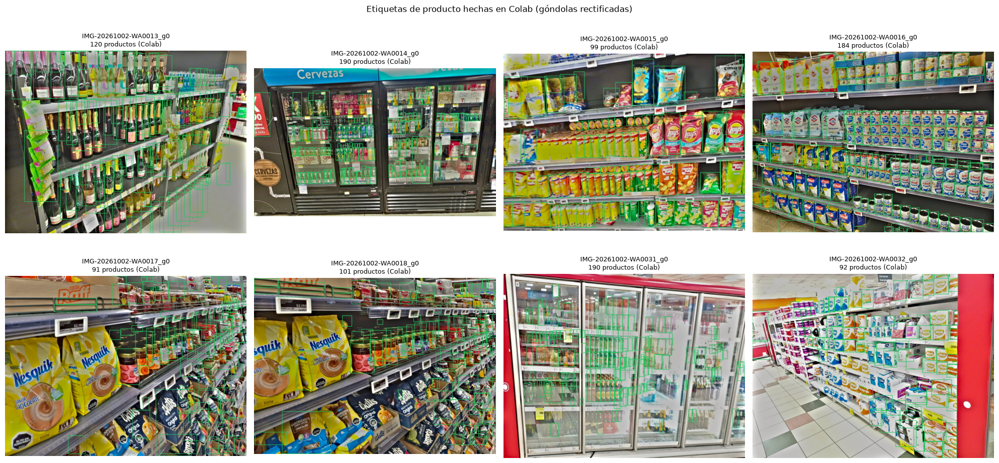

In [5]:
# [Celda 5] Ver las etiquetas que hiciste en Colab
N_MOSTRAR = 8

def leer_yolo_txt(texto, W, H):
    # Convierte líneas "clase xc yc w h" (normalizadas) a cajas en píxeles
    cajas = []
    for linea in texto.strip().splitlines():
        partes = linea.split()
        if len(partes) != 5:
            continue
        c, xc, yc, w, h = int(partes[0]), *map(float, partes[1:])
        cajas.append({"c": c, "b": [(xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H]})
    return cajas

carpeta = PERSIST_COLAB / "para_etiquetar_producto"
if carpeta.exists():
    imagenes = sorted((carpeta / "images").glob("*.jpg"))[:N_MOSTRAR]
    cols = 4
    fig, axes = plt.subplots(max(1, math.ceil(len(imagenes) / cols)), cols, figsize=(20, 5 * math.ceil(len(imagenes) / cols)))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, ruta in zip(np.atleast_1d(axes).ravel(), imagenes):
        img = np.array(Image.open(ruta).convert("RGB"))
        txt = carpeta / "labels" / f"{ruta.stem}.txt"
        cajas = leer_yolo_txt(txt.read_text(), img.shape[1], img.shape[0]) if txt.exists() else []
        for c in cajas:
            x1, y1, x2, y2 = map(int, c["b"])
            cv2.rectangle(img, (x1, y1), (x2, y2), (34, 197, 94), 2)
        ax.imshow(img)
        ax.set_title(f"{ruta.stem}\n{len(cajas)} productos (Colab)", fontsize=9)
    plt.suptitle("Etiquetas de producto hechas en Colab (góndolas rectificadas)")
    plt.tight_layout(); plt.show(); plt.close(fig)
else:
    print("No encontré", carpeta, "- se omite (no afecta al resto).")

## 2. Etiquetado automático (ensemble de detectores)

Cada **fuente** detecta por su cuenta y guarda sus cajas *crudas* (con confianza baja) en
`stockeye_v4/cache/<fuente>/`. Luego la celda 11 las **fusiona**:

| Fuente | Aporta | Fortaleza | Debilidad |
|---|---|---|---|
| `gondola_colab` | góndola | entrenado por ti en Colab | **casi siempre marca la foto entera** (así se entrenó en v2): solo se usa si su caja cubre <90 % de la foto |
| *grupos de productos* | góndola | productos vecinos agrupados → una góndola por mueble o lado del pasillo | depende de que se detecten los productos |
| `foduu` | producto + vacío | preciso en góndolas frontales | se le escapan productos en primeros planos |
| `maestro_hitl` | producto | entrenado con etiquetas humanas; ve muchos productos | falsos positivos (piso, carteles) |
| `gdino` (opcional) | producto | detección por texto | muy lento en CPU |
| `alumno` (ronda 2) | góndola + vacío | aprende de **tus** correcciones | existe solo después de entrenar el maestro |

Una caja en la que **coinciden 2+ fuentes** sube su confianza; una caja de **una sola fuente** debe
tener confianza alta y textura de producto. Todo queda en caché: solo se calcula una vez.

### Celda 6 · Utilidades de cajas y verificación de pesos

- **Qué hace:** Funciones comunes: IoU, NMS, mosaicos, *Weighted Boxes Fusion*, textura (bordes Canny), conversión a/desde YOLO y un **escaneo de seguridad** de archivos `.pt` (que solo contengan clases de PyTorch/Ultralytics antes de cargarlos).
- **Qué necesita:** Celda 2.
- **Qué deja listo:** Funciones `iou`, `nms`, `wbf`, `generar_mosaicos`, `densidad`, `escanear_pt`, `leer_revisada`, …
- **Tiempo y recursos:** Instantáneo.

In [6]:
# [Celda 6] Utilidades de cajas y verificación de pesos
# ---------- Geometría de cajas [x1, y1, x2, y2] ----------
def area(b):
    return max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])

def interseccion(a, b):
    return max(0.0, min(a[2], b[2]) - max(a[0], b[0])) * max(0.0, min(a[3], b[3]) - max(a[1], b[1]))

def iou(a, b):
    inter = interseccion(a, b)
    return inter / (area(a) + area(b) - inter + 1e-9)

def centro_dentro(b, g):
    xc, yc = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
    return g[0] <= xc <= g[2] and g[1] <= yc <= g[3]

def nms(cajas, umbral=0.5, contencion=0.8):
    # Mantiene la de mayor score y quita las que se le superponen o quedan casi dentro
    elegidas = []
    for c in sorted(cajas, key=lambda c: -c["score"]):
        if all(iou(c["box"], e["box"]) < umbral and
               interseccion(c["box"], e["box"]) < contencion * min(area(c["box"]), area(e["box"]))
               for e in elegidas):
            elegidas.append(c)
    return elegidas

def generar_mosaicos(W, H, grid, overlap):
    # Ventanas que cubren la foto con solape (grid x grid)
    if grid <= 1:
        return [(0, 0, W, H)]
    tw, th = int(W / (grid - (grid - 1) * overlap)), int(H / (grid - (grid - 1) * overlap))
    xs, ys = np.linspace(0, W - tw, grid).astype(int), np.linspace(0, H - th, grid).astype(int)
    return [(int(x), int(y), int(x) + tw, int(y) + th) for y in ys for x in xs]

def wbf(listas, pesos, umbral_iou):
    # Weighted Boxes Fusion: une cajas de varias fuentes que se refieren al mismo objeto.
    # listas: {fuente: [{"box", "score"}]} -> [{"box", "score", "n", "fuentes"}]
    todas = [(c["box"], c["score"] * pesos.get(f, 1.0), f) for f, lst in listas.items() for c in lst]
    todas.sort(key=lambda t: -t[1])
    grupos = []
    for box, score, fuente in todas:
        mejor, mejor_iou = None, umbral_iou
        for g in grupos:
            v = iou(box, g["box"])
            if v >= mejor_iou:
                mejor, mejor_iou = g, v
        if mejor is None:
            grupos.append({"box": list(box), "cajas": [(box, score, fuente)]})
        else:
            mejor["cajas"].append((box, score, fuente))
            ws = np.array([s for _, s, _ in mejor["cajas"]])
            bs = np.array([b for b, _, _ in mejor["cajas"]])
            mejor["box"] = list((bs * ws[:, None]).sum(0) / ws.sum())   # promedio ponderado
    salida = []
    for g in grupos:
        por_fuente = {}
        for _, s, f in g["cajas"]:
            por_fuente[f] = max(por_fuente.get(f, 0.0), s)          # mejor caja de cada fuente
        n = len(por_fuente)
        score = min(1.0, float(np.mean(list(por_fuente.values()))) + CFG["bonus_acuerdo"] * (n - 1))
        salida.append({"box": [float(v) for v in g["box"]], "score": score, "n": n,
                       "fuentes": sorted(por_fuente)})
    return salida

# ---------- Textura: los productos tienen muchos bordes, un vacío casi ninguno ----------
def mapa_bordes(img_bgr):
    gris = cv2.GaussianBlur(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    return (cv2.Canny(gris, 50, 150) > 0).astype(np.float32)

def densidad(bordes, b, margen=0.1):
    # Densidad de bordes dentro de la caja (ignora un 10 % del contorno)
    dx, dy = (b[2] - b[0]) * margen, (b[3] - b[1]) * margen
    x1, y1, x2, y2 = int(b[0] + dx), int(b[1] + dy), int(b[2] - dx), int(b[3] - dy)
    region = bordes[max(0, y1):max(0, y2), max(0, x1):max(0, x2)]
    return float(region.mean()) if region.size else 0.0

# ---------- Formato YOLO ----------
def a_linea_yolo(c, b, W, H):
    xc, yc = (b[0] + b[2]) / 2 / W, (b[1] + b[3]) / 2 / H
    return f"{c} {xc:.6f} {yc:.6f} {(b[2] - b[0]) / W:.6f} {(b[3] - b[1]) / H:.6f}"

def ruta_revisada(f):
    return REVISADAS_DIR / f"{f['ruta'].stem}.txt"

def leer_revisada(f):
    # Tus etiquetas guardadas desde el editor ([] si la foto no está revisada)
    ruta = ruta_revisada(f)
    return leer_yolo_txt(ruta.read_text(), f["W"], f["H"]) if ruta.exists() else []

def leer_yolo_txt(texto, W, H):
    cajas = []
    for linea in texto.strip().splitlines():
        partes = linea.split()
        if len(partes) == 5:
            c, xc, yc, w, h = int(partes[0]), *map(float, partes[1:])
            cajas.append({"c": c, "b": [(xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H]})
    return cajas

# ---------- Seguridad: revisar un .pt sin ejecutarlo ----------
MODULOS_PERMITIDOS = ("torch", "ultralytics", "collections", "builtins", "__builtin__", "numpy", "typing",
                      "omegaconf", "_codecs", "pathlib")

def escanear_pt(ruta):
    # Un .pt es un pickle: puede ejecutar código al cargarse. Aquí se leen sus "imports" sin ejecutarlo.
    sospechosos = set()
    with zipfile.ZipFile(ruta) as zf:
        for nombre in zf.namelist():
            if not nombre.endswith(".pkl"):
                continue
            textos = []
            for op, arg, _ in pickletools.genops(io.BytesIO(zf.read(nombre))):
                if op.name in ("SHORT_BINUNICODE", "BINUNICODE", "UNICODE"):
                    textos.append(arg)
                modulo = None
                if op.name == "GLOBAL":
                    modulo = str(arg).split()[0]
                elif op.name == "STACK_GLOBAL" and len(textos) >= 2:
                    modulo = textos[-2]
                if modulo and not modulo.startswith(MODULOS_PERMITIDOS):
                    sospechosos.add(modulo)
    if sospechosos:
        raise RuntimeError(f"{ruta.name} importa módulos no esperados: {sorted(sospechosos)}. No se carga.")
    return True

print("Utilidades listas.")

Utilidades listas.


### Celda 7 · Cargar los detectores (Colab + Hugging Face)

- **Qué hace:** Extrae de `Descargas/runs_pesos.zip` el **YOLO de góndola** y el **maestro HITL** que entrenaste en Colab, descarga el **YOLO de góndolas** de Hugging Face (foduu), revisa cada `.pt` con `escanear_pt` y los carga.
- **Qué necesita:** Celda 6. `runs_pesos.zip` en Descargas (si falta, esas fuentes se omiten).
- **Qué deja listo:** Diccionario `DETECTORES` con los modelos disponibles.
- **Tiempo y recursos:** Segundos (la descarga de foduu, ~22 MB, solo la primera vez).
- **Qué revisar:** La lista de detectores cargados y sus clases.

In [7]:
# [Celda 7] Cargar los detectores (Colab + Hugging Face)
from ultralytics import YOLO
from huggingface_hub import hf_hub_download

def extraer_de_zip(zip_path, miembro, destino):
    # Copia un solo archivo del zip (sin descomprimir todo)
    if not destino.exists():
        with zipfile.ZipFile(zip_path) as zf, zf.open(miembro) as src, open(destino, "wb") as dst:
            shutil.copyfileobj(src, dst)
    return destino

DETECTORES = {}

# 1) Modelos de Colab
if RUNS_ZIP_COLAB.exists():
    for clave, miembro in [("gondola_colab", "gondola/weights/best.pt"),
                           ("maestro_hitl", "maestro_hitl_yolo11n_512/weights/best.pt")]:
        try:
            ruta = extraer_de_zip(RUNS_ZIP_COLAB, miembro, PESOS_DIR / f"{clave}.pt")
            escanear_pt(ruta)
            DETECTORES[clave] = YOLO(str(ruta))
        except KeyError:
            print(f"No está {miembro} dentro de {RUNS_ZIP_COLAB.name}")
else:
    print(f"No encontré {RUNS_ZIP_COLAB}: se omiten la góndola y el maestro de Colab.")

# 2) YOLO de góndolas de Hugging Face (clases 'empty' y 'product')
ruta_foduu = PESOS_DIR / "foduu_gondolas_yolov8s.pt"
if not ruta_foduu.exists():
    shutil.copy2(hf_hub_download(CFG["foduu_repo"], CFG["foduu_archivo"]), ruta_foduu)
escanear_pt(ruta_foduu)
DETECTORES["foduu"] = YOLO(str(ruta_foduu))

for k, m in DETECTORES.items():
    print(f"  {k:14s} clases: {m.names}")

  gondola_colab  clases: {0: 'gondola'}
  maestro_hitl   clases: {0: 'producto', 1: 'precio'}
  foduu          clases: {0: 'empty', 1: 'product'}


### Celda 8 · Detecciones crudas por fuente (con caché)

- **Qué hace:** Corre cada detector sobre cada foto y guarda sus cajas en `cache/<fuente>/<foto>.json`:
  - `gondola_colab`: foto completa.
  - `foduu`: 3 escalas + mosaico 2×2 (productos grandes y pequeños).
  - `maestro_hitl`: mosaico 3×3 a 512 px (así fue entrenado en Colab); se ignora su clase `precio`.
- **Qué necesita:** Celda 7.
- **Qué deja listo:** Función `detecciones(f, fuente)` y `f['det']` con las cajas crudas de cada fuente.
- **Tiempo y recursos:** ~3 s por foto la primera vez (~10 min para 187 fotos); luego instantáneo.
- **Qué revisar:** Que el total de cajas por fuente no sea 0.

In [8]:
# [Celda 8] Detecciones crudas por fuente (con caché)
def a_lista(res, dx=0, dy=0):
    # Resultado de YOLO -> lista de (clase, caja, score) en coordenadas de la foto
    salida = []
    for b, c, s in zip(res.boxes.xyxy.tolist(), res.boxes.cls.tolist(), res.boxes.conf.tolist()):
        salida.append((int(c), [b[0] + dx, b[1] + dy, b[2] + dx, b[3] + dy], float(s)))
    return salida

def predecir_yolo(modelo, img, imgsz, mosaico=1, overlap=0.25, imgsz_tile=640):
    # Foto completa (+ mosaico opcional) y NMS por clase
    H, W = img.shape[:2]
    opciones = dict(conf=CFG["conf_cruda"], device=DEVICE, verbose=False)
    dets = []
    for sz in (imgsz if isinstance(imgsz, (list, tuple)) else [imgsz]):
        dets += a_lista(modelo.predict(img, imgsz=sz, **opciones)[0])
    if mosaico > 1:
        for (x1, y1, x2, y2) in generar_mosaicos(W, H, mosaico, overlap):
            dets += a_lista(modelo.predict(img[y1:y2, x1:x2], imgsz=imgsz_tile, **opciones)[0], x1, y1)
    if not dets:
        return []
    b = torch.tensor([d[1] for d in dets]); s = torch.tensor([d[2] for d in dets]); c = torch.tensor([d[0] for d in dets])
    keep = torchvision.ops.batched_nms(b, s, c, 0.5).tolist()
    return [dets[i] for i in keep]

def correr_fuente(fuente, img):
    # Devuelve {"gondola": [...], "producto": [...], "vacio": [...]} con cajas crudas
    out = {c: [] for c in ("gondola", "producto", "vacio")}   # siempre las 3 (producto sirve de guía)
    if fuente == "gondola_colab":
        for c, b, s in predecir_yolo(DETECTORES[fuente], img, 640):
            out["gondola"].append({"box": b, "score": s})
    elif fuente == "foduu":
        nombres = DETECTORES[fuente].names
        for c, b, s in predecir_yolo(DETECTORES[fuente], img, list(CFG["escalas"]), mosaico=2):
            out["vacio" if "empty" in nombres[c].lower() else "producto"].append({"box": b, "score": s})
    elif fuente == "maestro_hitl":
        nombres = DETECTORES[fuente].names
        for c, b, s in predecir_yolo(DETECTORES[fuente], img, 512, mosaico=CFG["maestro_tiles"], overlap=0.2, imgsz_tile=512):
            if nombres[c] == "producto":          # se descarta la clase 'precio'
                out["producto"].append({"box": b, "score": s})
    elif fuente == "alumno":
        for c, b, s in predecir_yolo(DETECTORES[fuente], img, CFG["imgsz"], mosaico=2, imgsz_tile=CFG["imgsz"]):
            out[CLASES[c]].append({"box": b, "score": s})
    return out

def detecciones(f, fuente, img=None):
    # Lee de la caché o calcula y guarda
    cache = CACHE_DIR / fuente / f"{f['ruta'].stem}.json"
    if cache.exists():
        return json.loads(cache.read_text())
    if img is None:
        img = cv2.imread(str(f["ruta"]))
    out = correr_fuente(fuente, img)
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_text(json.dumps(out))
    return out

FUENTES_YOLO = [k for k in ("gondola_colab", "foduu", "maestro_hitl") if k in DETECTORES]
t0 = time.time()
for i, f in enumerate(fotos, 1):
    vigilar_temperatura()                                      # pausa si la CPU está muy caliente
    pendientes = [k for k in FUENTES_YOLO if not (CACHE_DIR / k / f"{f['ruta'].stem}.json").exists()]
    img = cv2.imread(str(f["ruta"])) if pendientes else None    # lee la foto solo si hace falta
    f["det"] = {k: detecciones(f, k, img) for k in FUENTES_YOLO}
    if i % 20 == 0 or i == len(fotos):
        print(f"  {i}/{len(fotos)} fotos ({time.time() - t0:.0f} s)")

for k in FUENTES_YOLO:
    tot = {c: sum(len(f["det"][k].get(c, [])) for f in fotos) for c in ("gondola", "producto", "vacio")}
    print(f"  {k:14s}", tot)

  20/187 fotos (0 s)
  40/187 fotos (0 s)
  60/187 fotos (0 s)
  80/187 fotos (0 s)
  100/187 fotos (0 s)
  120/187 fotos (0 s)
  140/187 fotos (0 s)
  160/187 fotos (0 s)
  180/187 fotos (0 s)
  187/187 fotos (0 s)
  gondola_colab  {'gondola': 197, 'producto': 0, 'vacio': 0}
  foduu          {'gondola': 0, 'producto': 6715, 'vacio': 452}
  maestro_hitl   {'gondola': 0, 'producto': 53023, 'vacio': 0}


### Celda 9 · (Opcional) Grounding DINO como fuente extra

- **Qué hace:** Si `CFG['usar_gdino'] = True`, detecta productos a partir de texto con Grounding DINO tiny (mosaico 2×2) y lo agrega como fuente `gdino`.
- **Qué necesita:** Celda 8.
- **Qué deja listo:** `f['det']['gdino']` en cada foto.
- **Tiempo y recursos:** **~45 s por foto en tu CPU (~2.5 h)**. Ideal para dejarlo corriendo de noche; si lo interrumpes, continúa donde quedó.
- **Qué revisar:** Por defecto está desactivado y la celda no hace nada.

In [9]:
# [Celda 9] (Opcional) Grounding DINO como fuente extra
GDINO = {}

def cargar_gdino():
    if not GDINO:
        from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
        GDINO["proc"] = AutoProcessor.from_pretrained(CFG["gdino_id"])
        GDINO["modelo"] = AutoModelForZeroShotObjectDetection.from_pretrained(CFG["gdino_id"]).eval()
    return GDINO["proc"], GDINO["modelo"]

@torch.inference_mode()
def gdino_detectar(img_pil):
    proc, modelo = cargar_gdino()
    entradas = proc(images=img_pil, text=CFG["gdino_prompt"], return_tensors="pt")
    salidas = modelo(**entradas)
    kw = dict(text_threshold=0.20, target_sizes=[img_pil.size[::-1]])
    try:                                    # transformers nuevo: "threshold"
        res = proc.post_process_grounded_object_detection(salidas, entradas["input_ids"], threshold=0.25, **kw)[0]
    except TypeError:                       # transformers antiguo: "box_threshold"
        res = proc.post_process_grounded_object_detection(salidas, entradas["input_ids"], box_threshold=0.25, **kw)[0]
    return list(zip(res["boxes"].tolist(), res["scores"].tolist()))

def gdino_foto(f):
    cache = CACHE_DIR / "gdino" / f"{f['ruta'].stem}.json"
    if cache.exists():
        return json.loads(cache.read_text())
    img = Image.open(f["ruta"]).convert("RGB")
    cajas = []
    for (x1, y1, x2, y2) in generar_mosaicos(f["W"], f["H"], 2, 0.25):
        for b, s in gdino_detectar(img.crop((x1, y1, x2, y2))):
            cajas.append({"box": [b[0] + x1, b[1] + y1, b[2] + x1, b[3] + y1], "score": float(s)})
    out = {"gondola": [], "producto": nms(cajas), "vacio": []}
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_text(json.dumps(out))
    return out

if CFG["usar_gdino"]:
    t0 = time.time()
    for i, f in enumerate(fotos, 1):
        vigilar_temperatura()
        f["det"]["gdino"] = gdino_foto(f)
        if i % 5 == 0 or i == len(fotos):
            print(f"  {i}/{len(fotos)} | {(time.time() - t0) / i:.1f} s/foto")
    GDINO.clear(); gc.collect()             # libera ~1 GB de RAM
else:
    # Si ya existe caché de una corrida anterior, se usa igual
    for f in fotos:
        if (CACHE_DIR / "gdino" / f"{f['ruta'].stem}.json").exists():
            f["det"]["gdino"] = gdino_foto(f)
    print("Grounding DINO desactivado (CFG['usar_gdino'] = False).")

Grounding DINO desactivado (CFG['usar_gdino'] = False).


### Celda 10 · Vacíos sugeridos por geometría (conservadores)

- **Qué hace:** Sugiere huecos sin producto **dentro de cada góndola**, con reglas estrictas para no marcar piso, paredes ni bordes de repisa:
  1. Agrupa productos seguros en repisas (bordes inferiores alineados, ≥3 productos), corrigiendo la inclinación de la foto.
  2. Candidato = hueco **entre dos productos vecinos de la misma repisa**, ambos confiables, de `gap_min_ancho`–`gap_max_ancho` veces el ancho de producto y del alto de la repisa.
  3. Solo en fotos **frontales** (repisa casi horizontal) se buscan además repisas completas vacías y huecos en los extremos: en fotos de pasillo esas reglas generaban falsos vacíos.
  4. Se aceptan solo candidatos con **poca textura**, que no pisen productos y que no sean franjas.
- **Qué necesita:** Celda 6.
- **Qué deja listo:** Función `vacios_geometricos(productos, gondolas, bordes, W, H)`.
- **Tiempo y recursos:** Instantáneo (se usa en la celda 11).
- **Qué revisar:** Son **sugerencias**: aparecen punteadas en el editor para que las confirmes o borres.

In [11]:
# [Celda 10] Vacíos sugeridos por geometría (conservadores)
def pendiente_repisas(cajas):
    # Pendiente típica entre bordes inferiores de productos vecinos (0 = repisa horizontal)
    if len(cajas) < 4:
        return 0.0
    alto = np.median([b[3] - b[1] for b in cajas])
    pendientes = []
    for b in cajas:
        xc, yb = (b[0] + b[2]) / 2, b[3]
        vecinos = [o for o in cajas if 0 < (o[0] + o[2]) / 2 - xc < 3 * (b[2] - b[0]) and abs(o[3] - yb) < 0.5 * alto]
        if vecinos:
            o = min(vecinos, key=lambda o: (o[0] + o[2]) / 2 - xc)
            pendientes.append((o[3] - yb) / ((o[0] + o[2]) / 2 - xc))
    return float(np.clip(np.median(pendientes), -0.4, 0.4)) if pendientes else 0.0

def agrupar_repisas(cajas):
    # Productos con borde inferior a la misma altura = misma repisa
    if not cajas:
        return []
    alto_med = np.median([b[3] - b[1] for b in cajas])
    repisas = []
    for b in sorted(cajas, key=lambda b: b[3]):
        if repisas and abs(b[3] - np.median([c[3] for c in repisas[-1]])) < CFG["fila_tol"] * alto_med:
            repisas[-1].append(b)
        else:
            repisas.append([b])
    return [sorted(r, key=lambda b: b[0]) for r in repisas if len(r) >= CFG["min_prod_fila"]]

def candidatos_en_gondola(cajas, g, W, H):
    # Candidatos a vacío: se "endereza" la inclinación, se buscan huecos y se devuelven a la foto
    m = pendiente_repisas(cajas)
    frontal = abs(m) <= CFG["pendiente_max"]          # foto de frente (no de pasillo)
    x0 = (g[0] + g[2]) / 2
    enderezar = lambda b, signo: [b[0], b[1] - signo * m * ((b[0] + b[2]) / 2 - x0),
                                  b[2], b[3] - signo * m * ((b[0] + b[2]) / 2 - x0)]
    repisas = agrupar_repisas([enderezar(b, 1) for b in cajas])
    candidatos, info = [], []
    for r in repisas:
        base = float(np.median([b[3] for b in r]))
        alto = float(np.median([b[3] - b[1] for b in r]))
        ancho = float(np.median([b[2] - b[0] for b in r]))
        techo = base - alto
        info.append({"base": base, "techo": techo, "alto": alto, "x1": r[0][0], "x2": max(b[2] for b in r)})
        x_fin = r[0][2]
        for b in r[1:]:                                 # huecos entre vecinos de la misma repisa
            hueco = b[0] - x_fin
            if CFG["gap_min_ancho"] * ancho <= hueco <= CFG["gap_max_ancho"] * ancho:
                candidatos.append([x_fin, techo, b[0], base])
            x_fin = max(x_fin, b[2])
        if frontal:                                     # extremos: solo en fotos frontales
            if g[0] > 0.02 * W and CFG["gap_min_ancho"] * ancho <= r[0][0] - g[0] <= CFG["gap_max_ancho"] * ancho:
                candidatos.append([g[0], techo, r[0][0], base])
            if g[2] < 0.98 * W and CFG["gap_min_ancho"] * ancho <= g[2] - x_fin <= CFG["gap_max_ancho"] * ancho:
                candidatos.append([x_fin, techo, g[2], base])
    if frontal:                                         # repisa completa vacía: solo en fotos frontales
        for sup, inf in zip(info, info[1:]):
            x1, x2 = max(sup["x1"], inf["x1"]), min(sup["x2"], inf["x2"])
            solape = (x2 - x1) / max(1.0, min(sup["x2"] - sup["x1"], inf["x2"] - inf["x1"]))
            if solape >= CFG["repisa_solape_min"] and inf["techo"] - sup["base"] >= CFG["repisa_vacia_min"] * max(sup["alto"], inf["alto"]):
                candidatos.append([x1, sup["base"], x2, inf["techo"]])
    return [enderezar(c, -1) for c in candidatos]        # de vuelta a coordenadas de la foto

def vacios_geometricos(productos, gondolas, bordes, W, H):
    cajas = [p["box"] for p in productos]
    if len(cajas) < CFG["min_prod_fila"]:
        return []
    ref = np.median([densidad(bordes, b) for b in cajas]) + 1e-6      # textura típica de producto
    vacios = []
    for g in [g["box"] for g in gondolas]:
        dentro = [b for b in cajas if centro_dentro(b, g)]
        for c in candidatos_en_gondola(dentro, g, W, H):
            c = [max(g[0], c[0]), max(g[1], c[1]), min(g[2], c[2]), min(g[3], c[3])]
            w, h = c[2] - c[0], c[3] - c[1]
            if w < 12 or h < 12 or w / h > CFG["vacio_aspecto_max"]:     # muy chico o franja
                continue
            if densidad(bordes, c) >= CFG["textura_max_rel"] * ref:      # tiene textura: hay algo ahí
                continue
            if any(interseccion(c, b) > 0.3 * area(c) for b in cajas):   # pisa productos
                continue
            vacios.append({"box": c, "score": 0.5, "n": 1, "fuentes": ["geometria"]})
    return vacios

print("Funciones de vacíos listas.")

Funciones de vacíos listas.


### Celda 11 · Fusión: sugerencias automáticas por foto

- **Qué hace:** Combina todas las fuentes de cada foto:
  - **Productos (guía):** *Weighted Boxes Fusion* de foduu + maestro HITL (+ GDINO). Las cajas de una sola fuente deben tener textura de producto. No se entrenan (salvo `INCLUIR_PRODUCTO = True`), pero ayudan a encontrar góndolas y huecos.
  - **Góndolas:** se **agrupan los productos vecinos** (separación < ~1 producto) y cada grupo con ≥ `gondola_min_prod` productos es una góndola (su contorno). Se suman las del alumno (ronda 2) y las del modelo de Colab **solo si no cubren la foto entera**. Productos sueltos fuera de toda góndola (personas, piso, carteles) se descartan.
  - **Vacíos:** `empty` de foduu (+ alumno) + huecos geométricos de la celda 10.
- **Qué necesita:** Celdas 8–10.
- **Qué deja listo:** `f['auto']` (sugerencias con score) y `f['prioridad']` (para ordenar la revisión).
- **Tiempo y recursos:** ~30 s para 187 fotos.
- **Qué revisar:** La tabla resumen. **Puedes re-ejecutar esta celda tras cambiar parámetros** sin repetir detecciones.

In [12]:
# [Celda 11] Fusión: sugerencias automáticas por foto
def filtrar_formas(cajas, W, H):
    # Fuera cajas gigantes, formas absurdas y tamaños extremos respecto a la mediana
    cajas = [c for c in cajas if area(c["box"]) < CFG["prod_area_max"] * W * H]
    amin, amax = CFG["prod_aspecto"]
    cajas = [c for c in cajas if amin <= (c["box"][2] - c["box"][0]) / max(1.0, c["box"][3] - c["box"][1]) <= amax]
    if len(cajas) >= 3:
        med = np.median([area(c["box"]) for c in cajas])
        lo, hi = CFG["prod_area_rel"]
        cajas = [c for c in cajas if lo * med <= area(c["box"]) <= hi * med]
    return cajas

def gondolas_por_grupos(cajas_obj, W, H):
    # Agrupa objetos vecinos (productos y vacíos) y devuelve el contorno de cada grupo grande
    n = len(cajas_obj)
    if n < CFG["gondola_min_prod"]:
        return []
    B = np.array([c["box"] for c in cajas_obj])
    dx = CFG["gondola_union"] * np.median(B[:, 2] - B[:, 0])   # separación máx. horizontal
    dy = CFG["gondola_union"] * np.median(B[:, 3] - B[:, 1])   # separación máx. vertical
    padre = list(range(n))
    def raiz(i):
        while padre[i] != i:
            padre[i] = padre[padre[i]]
            i = padre[i]
        return i
    for i in range(n):
        # vecinos de i: cajas a menos de dx / dy de distancia (vectorizado con numpy)
        cerca = ((B[:, 0] - B[i, 2] < dx) & (B[i, 0] - B[:, 2] < dx) &
                 (B[:, 1] - B[i, 3] < dy) & (B[i, 1] - B[:, 3] < dy))
        for j in np.nonzero(cerca)[0]:
            padre[raiz(int(j))] = raiz(i)
    grupos = defaultdict(list)
    for i in range(n):
        grupos[raiz(i)].append(i)
    gondolas = []
    for idx in grupos.values():
        if len(idx) < CFG["gondola_min_prod"]:
            continue
        x1, y1, x2, y2 = B[idx, 0].min(), B[idx, 1].min(), B[idx, 2].max(), B[idx, 3].max()
        mx, my = CFG["gondola_margen"] * (x2 - x1), CFG["gondola_margen"] * (y2 - y1)
        score = float(np.mean([cajas_obj[i]["score"] for i in idx]))
        gondolas.append({"box": [max(0.0, x1 - mx), max(0.0, y1 - my), min(float(W), x2 + mx), min(float(H), y2 + my)],
                         "score": min(1.0, 0.5 + score / 2), "n": len(idx), "fuentes": ["grupos"]})
    # Une góndolas que se superponen mucho (el mismo mueble partido en dos grupos)
    unidas = True
    while unidas:
        unidas = False
        for a in range(len(gondolas)):
            for b in range(a + 1, len(gondolas)):
                ga, gb = gondolas[a]["box"], gondolas[b]["box"]
                if iou(ga, gb) > 0.3 or interseccion(ga, gb) > 0.6 * min(area(ga), area(gb)):
                    gondolas[a]["box"] = [min(ga[0], gb[0]), min(ga[1], gb[1]), max(ga[2], gb[2]), max(ga[3], gb[3])]
                    gondolas[a]["n"] += gondolas[b]["n"]
                    gondolas.pop(b)
                    unidas = True
                    break
            if unidas:
                break
    return gondolas

def tiene_vecino_lateral(b, productos):
    # ¿Hay un producto a la izquierda o derecha, a la misma altura? (el piso o una pared no lo tienen)
    w, h = b[2] - b[0], b[3] - b[1]
    for p in productos:
        q = p["box"]
        solape_v = min(b[3], q[3]) - max(b[1], q[1])                  # superposición vertical
        dist_h = max(q[0] - b[2], b[0] - q[2], 0.0)                    # distancia horizontal
        if solape_v >= 0.5 * min(h, q[3] - q[1]) and dist_h <= max(w, q[2] - q[0]):
            return True
    return False

def fusionar_foto(f):
    W, H = f["W"], f["H"]
    det = f["det"]
    pesos = CFG["pesos_fuente"]
    bordes = mapa_bordes(cv2.imread(str(f["ruta"])))

    # --- Productos (guía) ---
    fuentes_p = {k: det[k]["producto"] for k in ("foduu", "maestro_hitl", "gdino", "alumno")
                 if k in det and det[k].get("producto")}
    productos = filtrar_formas(wbf(fuentes_p, pesos, CFG["wbf_iou"]), W, H)
    if productos:
        dens = [densidad(bordes, p["box"]) for p in productos]
        ref = np.median([d for d, p in zip(dens, productos) if p["n"] >= 2] or dens) + 1e-6
        productos = [p for d, p in zip(dens, productos) if p["n"] >= 2 or d >= CFG["textura_min_rel"] * ref]

    # --- Vacíos detectados por modelos (también ayudan a delimitar la góndola) ---
    fuentes_v = {k: det[k]["vacio"] for k in ("foduu", "alumno") if k in det}
    vacios = [v for v in wbf(fuentes_v, pesos, 0.4) if v["score"] >= CFG["conf_vacio"]]

    # --- Góndolas: grupos de productos + alumno + Colab (si no marca la foto entera) ---
    confiables = [p for p in productos if p["score"] >= CFG["conf_auto"]]      # solo productos seguros
    gondolas = gondolas_por_grupos(confiables + vacios, W, H)
    for k in ("alumno", "gondola_colab"):
        for g in det.get(k, {}).get("gondola", []):
            if g["score"] >= CFG["conf_gondola"] and area(g["box"]) < CFG["gondola_cobertura_max"] * W * H:
                gondolas.append({"box": g["box"], "score": g["score"], "n": 1, "fuentes": [k]})
    gondolas = nms(gondolas, 0.5, contencion=0.9)
    if gondolas:                                        # fuera lo que quede suelto fuera de toda góndola
        dentro = lambda c: max(interseccion(c["box"], g["box"]) for g in gondolas) >= CFG["dentro_gondola"] * area(c["box"])
        productos = [p for p in productos if dentro(p)]
        vacios = [v for v in vacios if dentro(v)]

    # --- Vacíos geométricos dentro de cada góndola ---
    seguros = [p for p in productos if p["score"] >= CFG["conf_auto"]]
    vacios += vacios_geometricos(seguros, gondolas, bordes, W, H)
    vacios = [v for v in nms(vacios, 0.3) if not any(interseccion(v["box"], p["box"]) > 0.3 * area(v["box"]) for p in seguros)]
    vacios = [v for v in vacios if tiene_vecino_lateral(v["box"], seguros)]   # un hueco de repisa tiene productos al lado

    f["auto"] = {"gondola": gondolas, "producto": productos, "vacio": vacios}
    # Prioridad de revisión: fotos con más vacíos sugeridos (y dudosos) primero
    f["prioridad"] = len(vacios) + 0.5 * sum(0.3 <= v["score"] < 0.6 for v in vacios) + 0.2 * (not gondolas)

def vista_fuente(f, fuente):
    # Cajas de una fuente concreta como {clase: [cajas]} (para la galería)
    if fuente == "ensemble":
        return f["auto"]
    if fuente == "geometria":
        return {"gondola": [], "producto": [], "vacio": [v for v in f["auto"]["vacio"] if "geometria" in v.get("fuentes", [])]}
    return f["det"].get(fuente, {c: [] for c in ("gondola", "producto", "vacio")})

t0 = time.time()
for f in fotos:
    fusionar_foto(f)
resumen = pd.DataFrame([{"split": f["split"], **{c: len(f["auto"][c]) for c in ("gondola", "producto", "vacio")}}
                        for f in fotos])
print(resumen.groupby("split").sum())
print(f"Fusión lista en {time.time() - t0:.0f} s | fotos con vacíos sugeridos: {(resumen.vacio > 0).sum()} de {len(resumen)}"
      f" | fotos sin góndola: {(resumen.gondola == 0).sum()}")

       gondola  producto  vacio
split                          
train      203     36587    407
val         47      7694     96
Fusión lista en 27 s | fotos con vacíos sugeridos: 145 de 187 | fotos sin góndola: 4


## 3. Ver las fotos y sus cajas antes de editar

Dos formas de mirar:

- **Celda 12, grilla rápida:** miniaturas (imagen estática, siempre funciona).
- **Celda 14, visor interactivo:** una foto a la vez con zoom, mostrar/ocultar cada clase y elegir la
  **fuente** (`ensemble`, `foduu`, `maestro_hitl`, `gondola_colab`, `geometria`, `revisada`,
  `auto_vs_revisada`). El botón **✏️ Editar esta foto** la abre en modo edición.

Colores: 🟦 góndola · 🟥 vacío · ⬜ gris = productos automáticos (solo guía, no se entrenan).
Las cajas **punteadas** son sugerencias automáticas; las **continuas** son tuyas.

### Celda 12 · Galería rápida (grilla)

- **Qué hace:** Muestra miniaturas con las sugerencias automáticas (o tus etiquetas si la foto ya está revisada). Los productos se dibujan en gris fino como guía.
- **Qué necesita:** Celda 11.
- **Qué deja listo:** Solo una figura.
- **Tiempo y recursos:** Segundos.
- **Qué revisar:** Cambia `FILTRO_SPLIT`, `SOLO_CON_VACIOS`, `ORDEN`, `DESDE` y `N_GRILLA` para recorrer todas las fotos.

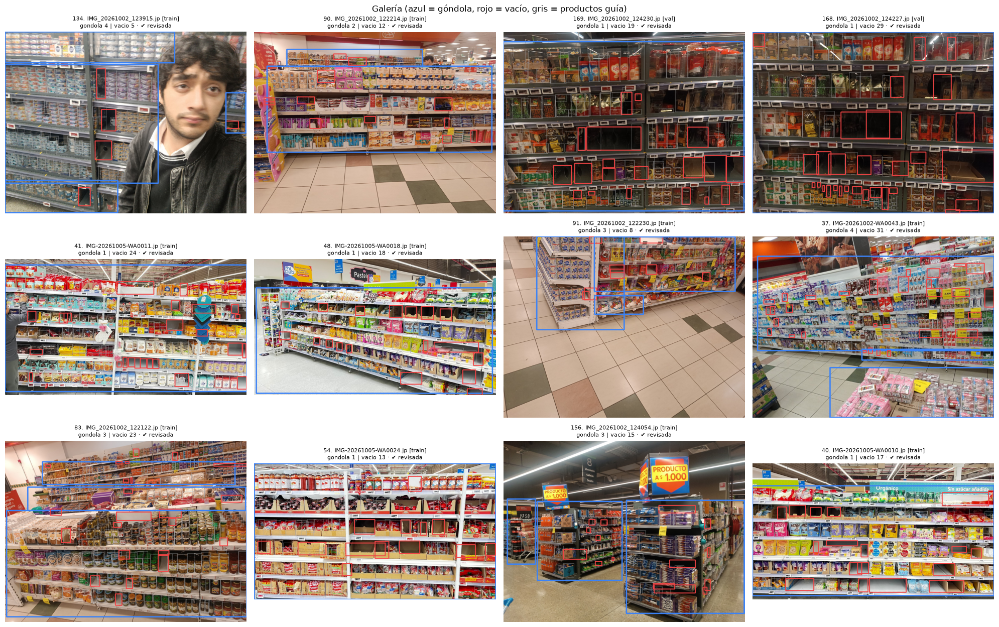

In [13]:
# [Celda 12] Galería rápida (grilla)
FILTRO_SPLIT = "todas"      # "todas" | "train" | "val"
SOLO_CON_VACIOS = False
ORDEN = "prioridad"         # "prioridad" (más vacíos sugeridos primero) | "nombre"
DESDE = 0                   # para ver las siguientes, súmale N_GRILLA
N_GRILLA = 12

def cajas_para_mostrar(f, conf=CFG["conf_auto"]):
    # Revisadas si existen; si no, sugerencias automáticas con confianza suficiente
    rev = leer_revisada(f)
    if ruta_revisada(f).exists():
        return [(c["c"], c["b"], False) for c in rev]
    return [(CLASES.index(k), c["box"], True) for k in CLASES for c in f["auto"][k] if c["score"] >= conf]

def dibujar_cajas(img_rgb, cajas, grosor=3, guias=()):
    # guias: productos en gris fino; cajas: (clase, caja, es_automatica)
    img = img_rgb.copy()
    for b in guias:
        x1, y1, x2, y2 = map(int, b)
        cv2.rectangle(img, (x1, y1), (x2, y2), COLOR_GUIA, 1)
    for c, b, auto in cajas:
        x1, y1, x2, y2 = map(int, b)
        g = (grosor + 2 if CLASES[c] == "gondola" else grosor) - (1 if auto else 0)
        cv2.rectangle(img, (x1, y1), (x2, y2), COLORES_RGB[c], max(1, g))
    return img

def guias_de(f):
    return [p["box"] for p in f["auto"]["producto"] if p["score"] >= 0.3] if not INCLUIR_PRODUCTO else []

lista = [f for f in fotos if FILTRO_SPLIT in ("todas", f["split"])]
if SOLO_CON_VACIOS:
    lista = [f for f in lista if any(CLASES[c] == "vacio" for c, _, _ in cajas_para_mostrar(f))]
lista = sorted(lista, key=(lambda f: -f["prioridad"]) if ORDEN == "prioridad" else (lambda f: f["nombre"]))
lista = lista[DESDE:DESDE + N_GRILLA]

cols = 4
filas = max(1, math.ceil(len(lista) / cols))
fig, axes = plt.subplots(filas, cols, figsize=(20, 4.3 * filas))
for ax in np.atleast_1d(axes).ravel():
    ax.axis("off")
for ax, f in zip(np.atleast_1d(axes).ravel(), lista):
    cajas = cajas_para_mostrar(f)
    img = cv2.cvtColor(cv2.imread(str(f["ruta"])), cv2.COLOR_BGR2RGB)
    ax.imshow(dibujar_cajas(img, cajas, guias=guias_de(f)))
    cuenta = " | ".join(f"{n} {sum(c == i for c, _, _ in cajas)}" for i, n in enumerate(CLASES))
    estado = "✔ revisada" if ruta_revisada(f).exists() else "sugerencias"
    ax.set_title(f"{fotos.index(f) + 1}. {f['nombre'][:22]} [{f['split']}]\n{cuenta} · {estado}", fontsize=8)
plt.suptitle("Galería (azul = góndola, rojo = vacío, gris = productos guía)")
plt.tight_layout(); plt.show(); plt.close(fig)

### Celda 13 · Widget del editor/visor de cajas

- **Qué hace:** Define el widget interactivo (`anywidget`, funciona en VS Code y JupyterLab) y la clase `Etiquetador`, que conecta el widget con las fotos: cargar, guardar, navegar, filtrar y pedir cajas automáticas por clase.
- **Qué necesita:** Celda 11.
- **Qué deja listo:** Clases `EditorCajas` y `Etiquetador`.
- **Tiempo y recursos:** Instantáneo.

**Cómo se usa el editor (celdas 14 y 16)**

| Acción | Cómo |
|---|---|
| Elegir clase para dibujar | botones `1 gondola` / `2 vacio` o teclas **1 2** (empieza en *vacio*) |
| Dibujar una caja | arrastrar sobre la foto |
| Seleccionar / mover | clic en la caja / arrastrarla |
| Redimensionar | arrastrar una esquina (cuadrito blanco) de la caja seleccionada |
| Borrar caja | **Supr** o **Retroceso** |
| Cambiar clase de la caja | **C** (o pulsar otro botón de clase con la caja seleccionada) |
| Ver productos guía | casilla **productos (guía)**: grises, no se guardan; ayudan a ver dónde falta mercadería |
| Zoom / mover vista | rueda del mouse / clic derecho o Shift + arrastrar · **F** ajusta |
| Sugerencias automáticas | `Auto gondola`, `Auto vacio`, `Auto todo` (reemplazan **solo** esa clase) |
| Filtrar sugerencias | deslizador **Confianza auto** · `Aceptar auto` (tecla **A**) las vuelve definitivas |
| Guardar / navegar | `💾 Guardar` (**S**), `◀ Anterior` (**P**), `Siguiente ▶` (**N**), `Ir` a la foto N |
| Filtro de fotos | Todas · Solo pendientes · Solo revisadas · **Con sugerencias** (pendientes con vacíos sugeridos) |

> Haz clic una vez sobre la foto para que el editor reciba las teclas. Al cambiar de foto, **los cambios se guardan solos**.
> Una foto **sin vacíos** también se debe guardar (💾): así el modelo aprende que ahí no hay quiebre.

In [14]:
# [Celda 13] Widget del editor/visor de cajas
import anywidget
import traitlets

# Código JavaScript del editor (dibuja la foto y las cajas en un <canvas>)
JS_EDITOR = r'''
// Editor de cajas para Jupyter (anywidget): ver, dibujar, mover y borrar cajas por clase
function crear(tag, clase, texto) {
  const e = document.createElement(tag);
  if (clase) e.className = clase;
  if (texto !== undefined) e.textContent = texto;
  return e;
}

function boton(texto, titulo, fn) {
  const b = crear("button", "se-btn", texto);
  b.title = titulo || "";
  b.onclick = fn;
  return b;
}

function render({ model, el }) {
  // ---------- Estado ----------
  let img = new Image();
  let cajas = [];            // [{c: clase, b: [x1, y1, x2, y2], auto: bool, s: score}]
  let sel = -1;              // índice de la caja seleccionada
  let clase = 0;             // clase activa para dibujar (al iniciar se elige "vacio")
  let verGuias = true;       // mostrar productos guía (gris)
  let visibles = [];         // clases visibles
  let s = 1, ox = 0, oy = 0; // vista: pantalla = imagen * s + o
  let drag = null;           // acción del mouse en curso
  let propio = false;        // evita bucles al sincronizar con Python

  const clases = () => model.get("clases");
  const colores = () => model.get("colores");
  const W = () => model.get("ancho");
  const H = () => model.get("alto");
  const lectura = () => model.get("solo_lectura");
  const enviar = (accion, extra) => model.send(Object.assign({ accion: accion }, extra || {}));

  // ---------- Interfaz ----------
  const raiz = crear("div", "se-raiz");
  const titulo = crear("div", "se-titulo");
  const filaClases = crear("div", "se-fila");
  const filaAuto = crear("div", "se-fila");
  const filaNav = crear("div", "se-fila");
  const canvas = crear("canvas", "se-canvas");
  canvas.tabIndex = 0;
  const estado = crear("div", "se-estado");
  const ayuda = crear("div", "se-ayuda");
  raiz.append(titulo, filaClases, filaAuto, filaNav, canvas, estado, ayuda);
  el.appendChild(raiz);

  // Botones de clase + casillas de visibilidad
  const botonesClase = [];
  const casillas = [];
  clases().forEach((nombre, i) => {
    visibles.push(true);
    const b = boton(`${i + 1} ${nombre}`, `Dibujar ${nombre} (tecla ${i + 1})`, () => elegirClase(i));
    b.style.borderColor = colores()[i];
    botonesClase.push(b);
    filaClases.appendChild(b);
  });
  filaClases.appendChild(crear("span", "se-sep", "Ver:"));
  clases().forEach((nombre, i) => {
    const etiqueta = crear("label", "se-check");
    const caja = crear("input");
    caja.type = "checkbox";
    caja.checked = true;
    caja.onchange = () => { visibles[i] = caja.checked; dibujar(); };
    casillas.push(caja);
    etiqueta.append(caja, document.createTextNode(" " + nombre));
    etiqueta.style.color = colores()[i];
    filaClases.appendChild(etiqueta);
  });
  // Casilla de productos guía (no se guardan; ayudan a ver dónde falta mercadería)
  const etiquetaGuia = crear("label", "se-check");
  const cajaGuia = crear("input");
  cajaGuia.type = "checkbox";
  cajaGuia.checked = true;
  cajaGuia.onchange = () => { verGuias = cajaGuia.checked; dibujar(); };
  etiquetaGuia.append(cajaGuia, document.createTextNode(" productos (guía)"));
  etiquetaGuia.style.color = "#aaaaaa";
  filaClases.appendChild(etiquetaGuia);
  // Selector de fuente (modo galería)
  const selFuente = crear("select", "se-select");
  selFuente.onchange = () => enviar("fuente", { valor: selFuente.value });
  const lblFuente = crear("span", "se-sep", "Fuente:");
  filaClases.append(lblFuente, selFuente);

  // Fila automática: confianza + botones auto por clase
  const lblConf = crear("span", "se-sep", "Confianza auto: 0.30");
  const slider = crear("input", "se-slider");
  slider.type = "range"; slider.min = "0"; slider.max = "1"; slider.step = "0.05";
  slider.oninput = () => {
    propio = true;
    model.set("conf", parseFloat(slider.value));
    model.save_changes();
    propio = false;
    lblConf.textContent = "Confianza auto: " + parseFloat(slider.value).toFixed(2);
    dibujar();
  };
  filaAuto.append(lblConf, slider);
  const botonesAuto = [];
  clases().forEach((nombre, i) => {
    const b = boton("Auto " + nombre, `Detectar ${nombre} automáticamente (reemplaza solo esa clase)`,
      () => enviar("auto", { clase: i }));
    botonesAuto.push(b);
    filaAuto.appendChild(b);
  });
  const bAutoTodo = boton("Auto todo", "Detectar las 3 clases automáticamente", () => enviar("auto", { clase: -1 }));
  const bAceptar = boton("Aceptar auto", "Convierte las cajas automáticas visibles en definitivas (tecla A)", aceptarAuto);
  const bBorrarClase = boton("Borrar clase", "Borra todas las cajas de la clase activa", borrarClase);
  filaAuto.append(bAutoTodo, bAceptar, bBorrarClase);

  // Fila de navegación
  const bAnt = boton("◀ Anterior", "Foto anterior (tecla P)", () => enviar("anterior"));
  const bGuardar = boton("💾 Guardar", "Guardar etiquetas de esta foto (tecla S)", () => enviar("guardar"));
  const bSig = boton("Siguiente ▶", "Foto siguiente (tecla N)", () => enviar("siguiente"));
  const inputIr = crear("input", "se-num");
  inputIr.type = "number"; inputIr.min = "1"; inputIr.value = "1";
  const bIr = boton("Ir", "Ir a la foto N", () => enviar("ir", { n: parseInt(inputIr.value || "1", 10) }));
  const selFiltro = crear("select", "se-select");
  [["todas", "Todas"], ["pendientes", "Solo pendientes"], ["revisadas", "Solo revisadas"],
   ["sugerencias", "Con sugerencias"]].forEach(([v, t]) => {
    const o = crear("option", null, t); o.value = v; selFiltro.appendChild(o);
  });
  selFiltro.onchange = () => enviar("filtro", { valor: selFiltro.value });
  const bAjustar = boton("⤢ Ajustar", "Ajustar la foto a la ventana (tecla F)", () => { ajustarVista(); dibujar(); });
  const bEditar = boton("✏️ Editar esta foto", "Abrir esta foto en modo edición", () => enviar("editar"));
  filaNav.append(bAnt, bGuardar, bSig, inputIr, bIr, selFiltro, bAjustar, bEditar);

  ayuda.textContent = "Arrastrar: dibujar caja · clic: seleccionar · arrastrar caja/esquina: mover/redimensionar · " +
    "Supr: borrar · C: cambiar clase · 1/2/3: clase activa · rueda: zoom · clic derecho o Shift+arrastrar: mover vista · " +
    "N/P: siguiente/anterior · S: guardar · A: aceptar auto · F: ajustar";

  // ---------- Utilidades ----------
  function elegirClase(i) {
    clase = i;
    botonesClase.forEach((b, k) => b.classList.toggle("se-activo", k === i));
    if (sel >= 0 && !lectura()) { cajas[sel].c = i; cajas[sel].auto = false; sincronizar(); }
    dibujar();
  }

  function visible(c) {
    return visibles[c.c] && !(c.auto && c.s < model.get("conf"));
  }

  function sincronizar() {
    propio = true;
    model.set("cajas", cajas.map(c => ({ c: c.c, b: c.b.slice(), auto: !!c.auto, s: c.s })));
    model.save_changes();
    propio = false;
  }

  function aImagen(ev) {
    const r = canvas.getBoundingClientRect();
    const px = (ev.clientX - r.left) * (canvas.width / r.width);
    const py = (ev.clientY - r.top) * (canvas.height / r.height);
    return [(px - ox) / s, (py - oy) / s, px, py];
  }

  function ajustarVista() {
    s = Math.min(canvas.width / W(), canvas.height / H());
    ox = (canvas.width - W() * s) / 2;
    oy = (canvas.height - H() * s) / 2;
  }

  function aceptarAuto() {
    if (lectura()) return;
    const conf = model.get("conf");
    cajas = cajas.filter(c => !c.auto || c.s >= conf).map(c => Object.assign(c, { auto: false }));
    sel = -1; sincronizar(); dibujar();
  }

  function borrarClase() {
    if (lectura()) return;
    cajas = cajas.filter(c => c.c !== clase);
    sel = -1; sincronizar(); dibujar();
  }

  function esquinaBajo(x, y) {
    // Devuelve 0..3 si (x, y) está sobre una esquina de la caja seleccionada
    if (sel < 0) return -1;
    const b = cajas[sel].b, t = 8 / s;
    const pts = [[b[0], b[1]], [b[2], b[1]], [b[2], b[3]], [b[0], b[3]]];
    for (let k = 0; k < 4; k++) {
      if (Math.abs(x - pts[k][0]) < t && Math.abs(y - pts[k][1]) < t) return k;
    }
    return -1;
  }

  function cajaBajo(x, y) {
    // La caja visible más pequeña que contiene el punto
    let mejor = -1, area = Infinity;
    cajas.forEach((c, i) => {
      if (!visible(c)) return;
      const b = c.b;
      if (x >= b[0] && x <= b[2] && y >= b[1] && y <= b[3]) {
        const a = (b[2] - b[0]) * (b[3] - b[1]);
        if (a < area) { area = a; mejor = i; }
      }
    });
    return mejor;
  }

  // ---------- Dibujo ----------
  function dibujar() {
    const ctx = canvas.getContext("2d");
    ctx.setTransform(1, 0, 0, 1, 0, 0);
    ctx.fillStyle = "#1e1e1e";
    ctx.fillRect(0, 0, canvas.width, canvas.height);
    ctx.setTransform(s, 0, 0, s, ox, oy);
    if (img.complete && img.naturalWidth > 0) ctx.drawImage(img, 0, 0, W(), H());
    if (verGuias) {                       // productos guía: gris fino, no editables
      ctx.setLineDash([]);
      ctx.lineWidth = 1 / s;
      ctx.strokeStyle = "rgba(200, 200, 200, 0.8)";
      model.get("guias").forEach(b => ctx.strokeRect(b[0], b[1], b[2] - b[0], b[3] - b[1]));
    }
    const cuenta = clases().map(() => 0);
    cajas.forEach((c, i) => {
      if (!visible(c)) return;
      cuenta[c.c] += 1;
      const b = c.b;
      ctx.setLineDash(c.auto ? [6 / s, 4 / s] : []);
      ctx.lineWidth = (i === sel ? 3.5 : 2) / s;
      ctx.strokeStyle = colores()[c.c];
      ctx.strokeRect(b[0], b[1], b[2] - b[0], b[3] - b[1]);
      if (i === sel) {
        ctx.setLineDash([]);
        ctx.fillStyle = "#ffffff";
        const t = 6 / s;
        [[b[0], b[1]], [b[2], b[1]], [b[2], b[3]], [b[0], b[3]]].forEach(p => ctx.fillRect(p[0] - t / 2, p[1] - t / 2, t, t));
      }
    });
    if (drag && drag.tipo === "dibujar") {
      ctx.setLineDash([]);
      ctx.lineWidth = 2 / s;
      ctx.strokeStyle = colores()[clase];
      ctx.strokeRect(drag.x0, drag.y0, drag.x - drag.x0, drag.y - drag.y0);
    }
    ctx.setLineDash([]);
    const textos = clases().map((n, i) => `${n}: ${cuenta[i]}`).join(" · ");
    const nAuto = cajas.filter(c => c.auto && visible(c)).length;
    estado.textContent = `${textos}${nAuto ? " · (" + nAuto + " automáticas sin aceptar, punteadas)" : ""} · ${model.get("progreso")}`;
  }

  // ---------- Mouse ----------
  canvas.addEventListener("contextmenu", ev => ev.preventDefault());

  canvas.addEventListener("mousedown", ev => {
    canvas.focus();
    const [x, y, px, py] = aImagen(ev);
    if (ev.button === 2 || ev.button === 1 || ev.shiftKey || lectura()) {
      // Mover la vista (y en modo lectura, seleccionar para resaltar)
      if (lectura() && ev.button === 0 && !ev.shiftKey) { sel = cajaBajo(x, y); dibujar(); }
      drag = { tipo: "pan", px: px, py: py, ox: ox, oy: oy };
      return;
    }
    const esquina = esquinaBajo(x, y);
    if (esquina >= 0) { drag = { tipo: "redim", k: esquina }; return; }
    const i = cajaBajo(x, y);
    if (i >= 0) {
      sel = i;
      drag = { tipo: "mover", x: x, y: y, b: cajas[i].b.slice(), movio: false };
      dibujar();
      return;
    }
    sel = -1;
    drag = { tipo: "dibujar", x0: x, y0: y, x: x, y: y };
    dibujar();
  });

  window.addEventListener("mousemove", ev => {
    if (!drag) return;
    const [x, y, px, py] = aImagen(ev);
    if (drag.tipo === "pan") {
      ox = drag.ox + (px - drag.px);
      oy = drag.oy + (py - drag.py);
    } else if (drag.tipo === "dibujar") {
      drag.x = Math.max(0, Math.min(W(), x));
      drag.y = Math.max(0, Math.min(H(), y));
    } else if (drag.tipo === "mover") {
      const dx = x - drag.x, dy = y - drag.y;
      const b = drag.b;
      cajas[sel].b = [b[0] + dx, b[1] + dy, b[2] + dx, b[3] + dy];
      drag.movio = true;
    } else if (drag.tipo === "redim") {
      const b = cajas[sel].b;
      if (drag.k === 0 || drag.k === 3) b[0] = x; else b[2] = x;
      if (drag.k === 0 || drag.k === 1) b[1] = y; else b[3] = y;
    }
    dibujar();
  });

  window.addEventListener("mouseup", () => {
    if (!drag) return;
    const d = drag;
    drag = null;
    if (d.tipo === "dibujar") {
      const b = [Math.min(d.x0, d.x), Math.min(d.y0, d.y), Math.max(d.x0, d.x), Math.max(d.y0, d.y)];
      if (b[2] - b[0] > 4 && b[3] - b[1] > 4) {
        cajas.push({ c: clase, b: b, auto: false, s: 1.0 });
        sel = cajas.length - 1;
        sincronizar();
      }
    } else if ((d.tipo === "mover" && d.movio) || d.tipo === "redim") {
      const b = cajas[sel].b;
      cajas[sel].b = [Math.min(b[0], b[2]), Math.min(b[1], b[3]), Math.max(b[0], b[2]), Math.max(b[1], b[3])];
      cajas[sel].auto = false;   // al editarla pasa a ser definitiva
      sincronizar();
    }
    dibujar();
  });

  canvas.addEventListener("wheel", ev => {
    ev.preventDefault();
    const [, , px, py] = aImagen(ev);
    const k = ev.deltaY < 0 ? 1.15 : 1 / 1.15;
    ox = px - (px - ox) * k;
    oy = py - (py - oy) * k;
    s *= k;
    dibujar();
  }, { passive: false });

  // ---------- Teclado ----------
  canvas.addEventListener("keydown", ev => {
    ev.stopPropagation();   // que Jupyter no interprete las teclas como comandos
    const t = ev.key.toLowerCase();
    const n = parseInt(ev.key, 10);
    if (n >= 1 && n <= clases().length) { elegirClase(n - 1); }
    else if ((t === "delete" || t === "backspace") && sel >= 0 && !lectura()) {
      cajas.splice(sel, 1); sel = -1; sincronizar(); dibujar();
    }
    else if (t === "c" && sel >= 0 && !lectura()) {
      cajas[sel].c = (cajas[sel].c + 1) % clases().length; cajas[sel].auto = false; sincronizar(); dibujar();
    }
    else if (t === "a") aceptarAuto();
    else if (t === "n" || t === "arrowright") enviar("siguiente");
    else if (t === "p" || t === "arrowleft") enviar("anterior");
    else if (t === "s") enviar("guardar");
    else if (t === "f") { ajustarVista(); dibujar(); }
    else if (t === "escape") { sel = -1; dibujar(); }
    else return;
    ev.preventDefault();
  });

  // ---------- Sincronización con Python ----------
  function cargarImagen() {
    img = new Image();
    img.onload = () => { ajustarVista(); dibujar(); };
    img.src = model.get("imagen");
  }

  function aplicarModo() {
    const ro = lectura();
    filaAuto.style.display = ro ? "none" : "";
    [bGuardar, bAceptar].forEach(b => { b.style.display = ro ? "none" : ""; });
    botonesClase.forEach(b => { b.style.display = ro ? "none" : ""; });
    bEditar.style.display = ro ? "" : "none";
    const fuentes = model.get("fuentes");
    selFuente.innerHTML = "";
    fuentes.forEach(f => { const o = crear("option", null, f); o.value = f; selFuente.appendChild(o); });
    selFuente.value = model.get("fuente");
    selFuente.style.display = ro && fuentes.length ? "" : "none";
    lblFuente.style.display = selFuente.style.display;
  }

  function redimensionar() {
    const ancho = Math.max(480, Math.floor(raiz.clientWidth || 1000));
    if (ancho !== canvas.width || canvas.height !== model.get("alto_vista")) {
      canvas.width = ancho;
      canvas.height = model.get("alto_vista");
      ajustarVista();
      dibujar();
    }
  }

  model.on("change:imagen", cargarImagen);
  model.on("change:cajas", () => {
    if (propio) return;
    cajas = model.get("cajas").map(c => ({ c: c.c, b: c.b.slice(), auto: !!c.auto, s: c.s }));
    sel = -1;
    dibujar();
  });
  model.on("change:titulo", () => { titulo.textContent = model.get("titulo"); });
  model.on("change:guias", dibujar);
  model.on("change:progreso", dibujar);
  model.on("change:solo_lectura", () => { aplicarModo(); dibujar(); });
  model.on("change:fuente", () => { selFuente.value = model.get("fuente"); });
  model.on("change:conf", () => {
    if (propio) return;
    slider.value = String(model.get("conf"));
    lblConf.textContent = "Confianza auto: " + model.get("conf").toFixed(2);
    dibujar();
  });

  // Estado inicial
  cajas = model.get("cajas").map(c => ({ c: c.c, b: c.b.slice(), auto: !!c.auto, s: c.s }));
  titulo.textContent = model.get("titulo");
  slider.value = String(model.get("conf"));
  lblConf.textContent = "Confianza auto: " + model.get("conf").toFixed(2);
  elegirClase(Math.max(0, clases().indexOf("vacio")));
  aplicarModo();
  canvas.width = 1000;
  canvas.height = model.get("alto_vista");
  cargarImagen();
  if (typeof ResizeObserver !== "undefined") new ResizeObserver(redimensionar).observe(raiz);
}

export default { render };
'''

# Estilos del editor
CSS_EDITOR = r'''
.se-raiz { font-family: system-ui, sans-serif; font-size: 13px; color: #ddd; background: #2b2b2b; padding: 8px; border-radius: 8px; }
.se-titulo { font-weight: 600; font-size: 14px; margin-bottom: 6px; }
.se-fila { display: flex; flex-wrap: wrap; gap: 6px; align-items: center; margin-bottom: 6px; }
.se-btn { background: #3c3c3c; color: #eee; border: 2px solid #555; border-radius: 5px; padding: 3px 9px; cursor: pointer; }
.se-btn:hover { background: #4a4a4a; }
.se-activo { background: #5a5a5a; font-weight: 700; box-shadow: 0 0 0 2px #fff inset; }
.se-sep { margin-left: 8px; color: #aaa; }
.se-check { cursor: pointer; user-select: none; }
.se-select, .se-num { background: #3c3c3c; color: #eee; border: 1px solid #555; border-radius: 4px; padding: 2px 4px; }
.se-num { width: 60px; }
.se-slider { width: 140px; }
.se-canvas { display: block; width: 100%; border: 1px solid #555; border-radius: 4px; cursor: crosshair; outline: none; }
.se-canvas:focus { border-color: #8ab4f8; }
.se-estado { margin-top: 6px; color: #ccc; }
.se-ayuda { margin-top: 4px; color: #888; font-size: 11px; }
'''


class EditorCajas(anywidget.AnyWidget):
    # Widget: los atributos con sync=True se comparten entre Python y el navegador
    _esm = JS_EDITOR
    _css = CSS_EDITOR
    imagen = traitlets.Unicode("").tag(sync=True)        # foto en base64 (data URL)
    ancho = traitlets.Int(1).tag(sync=True)
    alto = traitlets.Int(1).tag(sync=True)
    cajas = traitlets.List([]).tag(sync=True)            # [{"c", "b", "auto", "s"}]
    guias = traitlets.List([]).tag(sync=True)            # productos guía [[x1, y1, x2, y2], ...]
    clases = traitlets.List(CLASES).tag(sync=True)
    colores = traitlets.List(COLORES_HEX).tag(sync=True)
    titulo = traitlets.Unicode("").tag(sync=True)
    progreso = traitlets.Unicode("").tag(sync=True)
    conf = traitlets.Float(0.3).tag(sync=True)
    solo_lectura = traitlets.Bool(False).tag(sync=True)
    fuentes = traitlets.List([]).tag(sync=True)
    fuente = traitlets.Unicode("ensemble").tag(sync=True)
    alto_vista = traitlets.Int(680).tag(sync=True)

FUENTES_VISOR = ["ensemble", "revisada", "auto_vs_revisada", "foduu", "maestro_hitl", "gondola_colab", "geometria", "gdino", "alumno"]

def foto_base64(ruta):
    return "data:image/jpeg;base64," + base64.b64encode(Path(ruta).read_bytes()).decode()

def a_editor(cajas_por_clase, auto=True):
    # {clase: [{"box","score"}]} -> formato del widget (solo las clases del modelo)
    return [{"c": CLASES.index(k), "b": [float(v) for v in c["box"]], "auto": auto, "s": float(c.get("score", 1.0))}
            for k in CLASES for c in cajas_por_clase.get(k, [])]

class Etiquetador:
    # Conecta el widget con las fotos: navegación, guardado y sugerencias automáticas
    def __init__(self, fotos, orden=None, solo_lectura=False, fuente="ensemble", modo=MODO_ETIQUETADO):
        self.todas = list(orden or fotos)
        self.lista = list(self.todas)
        self.i = 0
        self.modo = modo
        self.inicial = []
        disponibles = {k for f in fotos for k in f["det"]}
        self.w = EditorCajas(solo_lectura=solo_lectura, fuente=fuente, conf=CFG["conf_editor"],
                             fuentes=[x for x in FUENTES_VISOR if x in ("ensemble", "revisada", "auto_vs_revisada", "geometria")
                                      or x in disponibles])
        self.w.on_msg(self._mensaje)
        self.cargar(0)

    # ---- Fotos y cajas ----
    @property
    def foto(self):
        return self.lista[self.i]

    def cajas_iniciales(self, f):
        rev = [{"c": c["c"], "b": c["b"], "auto": False, "s": 1.0} for c in leer_revisada(f)]
        if self.w.solo_lectura:                       # visor: según la fuente elegida
            fuente = self.w.fuente
            if fuente == "revisada":
                return rev
            if fuente == "auto_vs_revisada":
                return rev + a_editor(f["auto"])
            return a_editor(vista_fuente(f, fuente))
        if ruta_revisada(f).exists():                 # editor: tus etiquetas mandan
            return rev
        return a_editor(f["auto"]) if self.modo == "mixto" else []

    def cargar(self, i):
        if not self.lista:
            self.w.titulo = "No hay fotos con este filtro."
            return
        self.i = int(np.clip(i, 0, len(self.lista) - 1))
        f = self.foto
        self.w.ancho, self.w.alto = f["W"], f["H"]
        self.w.imagen = foto_base64(f["ruta"])
        self.w.guias = [[float(v) for v in b] for b in guias_de(f)]
        self.inicial = self.cajas_iniciales(f)
        self.w.cajas = [dict(c) for c in self.inicial]
        estado = "✔ revisada" if ruta_revisada(f).exists() else "pendiente"
        self.w.titulo = f"[{self.i + 1}/{len(self.lista)}] {f['nombre']} · {f['split']} · {estado}"
        self.actualizar_progreso()

    def actualizar_progreso(self):
        n_rev = sum(ruta_revisada(f).exists() for f in self.todas)
        n_val = sum(ruta_revisada(f).exists() for f in self.todas if f["split"] == "val")
        t_val = sum(f["split"] == "val" for f in self.todas)
        self.w.progreso = f"Revisadas: {n_rev}/{len(self.todas)} (val {n_val}/{t_val})"

    def guardar(self):
        # Guarda las cajas definitivas y las sugerencias visibles (score >= deslizador)
        f = self.foto
        lineas = []
        for c in self.w.cajas:
            if c["auto"] and c["s"] < self.w.conf:
                continue
            b = [float(np.clip(c["b"][0], 0, f["W"])), float(np.clip(c["b"][1], 0, f["H"])),
                 float(np.clip(c["b"][2], 0, f["W"])), float(np.clip(c["b"][3], 0, f["H"]))]
            if b[2] - b[0] > 2 and b[3] - b[1] > 2:
                lineas.append(a_linea_yolo(int(c["c"]), b, f["W"], f["H"]))
        ruta_revisada(f).write_text("\n".join(lineas))     # archivo vacío = foto revisada sin cajas
        self.inicial = [dict(c) for c in self.w.cajas]
        self.w.titulo = self.w.titulo.replace("pendiente", "✔ revisada")
        self.actualizar_progreso()

    def hubo_cambios(self):
        return not self.w.solo_lectura and self.w.cajas != self.inicial

    def auto(self, clase_idx):
        # Reemplaza solo las cajas de la clase pedida (o todas si clase_idx = -1) por las sugeridas
        nuevas = a_editor(self.foto["auto"])
        if clase_idx >= 0:
            nuevas = [c for c in nuevas if c["c"] == clase_idx]
            otras = [c for c in self.w.cajas if c["c"] != clase_idx]
        else:
            otras = []
        self.w.cajas = otras + nuevas

    def filtrar(self, valor):
        actual = self.foto["nombre"] if self.lista else None
        revisada = lambda f: ruta_revisada(f).exists()
        criterio = {"todas": lambda f: True, "pendientes": lambda f: not revisada(f),
                    "revisadas": revisada,
                    "sugerencias": lambda f: not revisada(f) and len(f["auto"]["vacio"]) > 0}[valor]
        self.lista = [f for f in self.todas if criterio(f)]
        nombres = [f["nombre"] for f in self.lista]
        self.cargar(nombres.index(actual) if actual in nombres else 0)

    # ---- Mensajes del navegador ----
    def _mensaje(self, widget, contenido, buffers):
        accion = contenido.get("accion", "")
        try:
            if accion in ("anterior", "siguiente", "ir") and self.hubo_cambios():
                self.guardar()                         # autoguardado al cambiar de foto
            if accion == "anterior":
                self.cargar(self.i - 1)
            elif accion == "siguiente":
                self.cargar(self.i + 1)
            elif accion == "ir":
                self.cargar(int(contenido.get("n", 1)) - 1)
            elif accion == "guardar":
                self.guardar()
            elif accion == "auto":
                self.auto(int(contenido.get("clase", -1)))
            elif accion == "fuente":
                self.w.fuente = contenido.get("valor", "ensemble")
                self.cargar(self.i)
            elif accion == "editar":
                self.w.solo_lectura = False
                self.cargar(self.i)
            elif accion == "filtro":
                self.filtrar(contenido.get("valor", "todas"))
        except Exception as ex:                        # el error se ve en la barra de estado
            self.w.progreso = f"⚠️ Error: {ex}"

print("Editor listo.")

Editor listo.


### Celda 14 · Visor interactivo (solo lectura)

- **Qué hace:** Abre el visor con todas las fotos, primero las que tienen más vacíos sugeridos. Permite comparar fuentes y ver tus correcciones (`auto_vs_revisada`).
- **Qué necesita:** Celda 13.
- **Qué deja listo:** El objeto `visor` (puedes navegar con sus botones).
- **Tiempo y recursos:** Instantáneo.
- **Qué revisar:** Elige la **Fuente** arriba para ver qué aporta cada detector. Si el widget no aparece, usa la celda 12.

In [15]:
# [Celda 14] Visor interactivo (solo lectura)
orden_visor = sorted(fotos, key=lambda f: -f["prioridad"])
visor = Etiquetador(fotos, orden=orden_visor, solo_lectura=True, fuente="ensemble")
display(visor.w)

## 4. Revisión humana: marcar góndolas y vacíos

Aquí haces que las etiquetas queden **realmente bien**. Solo hay 2 clases que marcar:

- 🟦 **góndola**: el mueble completo (estantería, refrigerador, isla). Una caja por mueble o por tramo visible.
- 🟥 **vacío**: cada espacio de repisa donde **debería haber producto y no hay** (se ve el fondo o la repisa).

Recomendación de trabajo (~1 minuto por foto):

1. Revisa **todas las fotos de validación** (39): así las métricas finales son reales.
2. Revisa ~40 fotos de train (la celda 15 las ordena: primero las que tienen más vacíos sugeridos).
3. Entrena el maestro (celda 19); te propondrá vacíos en el resto y solo tendrás que **aceptar o borrar**
   (filtro **Con sugerencias**).

> Una foto revisada **sin vacíos** también vale (guárdala con 💾): enseña al modelo cómo es una góndola llena.

### Celda 15 · Fotos sugeridas para revisar

- **Qué hace:** Arma la lista de revisión: primero todas las de **val**, luego las de train con más vacíos sugeridos, alternando tipo de foto (nativa / WhatsApp) para tener variedad de ángulos.
- **Qué necesita:** Celda 11.
- **Qué deja listo:** `orden_revision` (lista de fotos para el editor).
- **Tiempo y recursos:** Instantáneo.
- **Qué revisar:** Cuántas fotos quedan sugeridas y cuántas ya revisaste.

In [16]:
# [Celda 15] Fotos sugeridas para revisar
val = sorted([f for f in fotos if f["split"] == "val"], key=lambda f: -f["prioridad"])
train = sorted([f for f in fotos if f["split"] == "train"], key=lambda f: -f["prioridad"])

# Train: alterna tipos de foto para tener variedad de ángulos
por_tipo = defaultdict(list)
for f in train:
    por_tipo[f["tipo"]].append(f)
sugeridas_train = []
while len(sugeridas_train) < CFG["n_revisar_train"] and any(por_tipo.values()):
    for tipo in list(por_tipo):
        if por_tipo[tipo] and len(sugeridas_train) < CFG["n_revisar_train"]:
            sugeridas_train.append(por_tipo[tipo].pop(0))

sugeridas = val + sugeridas_train
orden_revision = sugeridas + [f for f in fotos if f not in sugeridas]   # después, cualquier otra foto
n_rev = sum(ruta_revisada(f).exists() for f in sugeridas)
print(f"Sugeridas: {len(sugeridas)} (val {len(val)} + train {len(sugeridas_train)}) | ya revisadas: {n_rev}")

Sugeridas: 79 (val 39 + train 40) | ya revisadas: 78


### Celda 16 · Editor de etiquetas

- **Qué hace:** Abre el editor sobre `orden_revision`. Guarda en `stockeye_v4/etiquetas_revisadas/<foto>.txt` (formato YOLO); esas etiquetas **siempre mandan** sobre las sugerencias.
- **Qué necesita:** Celdas 13 y 15.
- **Qué deja listo:** Tus etiquetas en disco (persisten aunque cierres el notebook).
- **Tiempo y recursos:** Lo que tú quieras: puedes revisar algunas, seguir y volver después.
- **Qué revisar:** La barra de estado muestra `Revisadas: N/M (val x/39)`. Con `MODO_ETIQUETADO = 'automatico'` no se abre.

In [17]:
# [Celda 16] Editor de etiquetas
if MODO_ETIQUETADO == "automatico":
    print("Modo automático: se usan solo las sugerencias (no se abre el editor).")
else:
    editor = Etiquetador(fotos, orden=orden_revision, solo_lectura=False, modo=MODO_ETIQUETADO)
    display(editor.w)

### Celda 17 · Resumen de la revisión

- **Qué hace:** Cuenta cuántas fotos revisaste por split y cuántas góndolas/vacíos marcaste frente a lo sugerido.
- **Qué necesita:** Celda 16 (o etiquetas de una sesión anterior).
- **Qué deja listo:** Tabla resumen.
- **Tiempo y recursos:** Instantáneo.
- **Qué revisar:** Ideal antes de entrenar: **todas las de val** y al menos ~30 de train revisadas.

In [18]:
# [Celda 17] Resumen de la revisión
filas = []
for f in fotos:
    if not ruta_revisada(f).exists():
        continue
    rev = leer_revisada(f)
    filas.append({"split": f["split"],
                  **{f"{k}_tuyas": sum(c["c"] == i for c in rev) for i, k in enumerate(CLASES)},
                  **{f"{k}_sugeridas": sum(c["score"] >= CFG["conf_auto"] for c in f["auto"][k]) for k in CLASES}})
tabla_rev = pd.DataFrame(filas)
if len(tabla_rev):
    print(tabla_rev.groupby("split").size().rename("fotos revisadas").to_string(), "\n")
    print(tabla_rev.groupby("split").sum().to_string())
else:
    print("Aún no hay fotos revisadas.")

split
train    148
val       39 

       gondola_tuyas  vacio_tuyas  gondola_sugeridas  vacio_sugeridas
split                                                                
train            273         1024                202              389
val               51          264                 47               90


## 5. Entrenamiento con aprendizaje activo (YOLO26)

**¿Por qué YOLO26?** Es la generación más nueva de Ultralytics (incluida en tu versión 8.4): no usa NMS,
es más rápido en CPU que YOLOv8/YOLO11 y tiene igual o mejor precisión. El YOLOv8 de foduu se usa **solo**
como detector automático de ayuda.

**Por qué solo con fotos revisadas:** si una foto tiene un vacío que nadie marcó, el modelo aprende que
eso es "fondo" y deja de detectar vacíos. Por eso:

1. **Ronda 1 (celda 19):** el maestro se entrena **solo con tus fotos revisadas**.
2. **Celda 20:** el maestro propone góndolas y vacíos en las fotos **no revisadas**. Abre el editor
   (celda 16), elige el filtro **Con sugerencias** y acepta/borra: es muy rápido.
3. **Ronda final (celda 21):** se entrena con todas las fotos revisadas (incluidas las aceptadas).

### Celda 18 · Crear el dataset YOLO

- **Qué hace:** Define `crear_dataset()`: escribe `dataset/images|labels/{train,val}` y `data.yaml` usando **solo fotos revisadas** (con `CFG['usar_no_revisadas'] = True` agrega las demás con sus sugerencias). Si hay muy pocas revisadas, avisa y completa con sugerencias para poder entrenar igual.
- **Qué necesita:** Celda 11 (y tus etiquetas de la celda 16).
- **Qué deja listo:** Función `crear_dataset()` y `DATA_YAML`.
- **Tiempo y recursos:** Segundos (las imágenes se enlazan, no se copian).
- **Qué revisar:** Cuántas fotos entran por split.

In [19]:
# [Celda 18] Crear el dataset YOLO
MIN_REVISADAS = 10      # por debajo de esto se completa con sugerencias automáticas (con aviso)

def etiquetas_finales(f):
    # Tus etiquetas mandan; si no hay, sugerencias con confianza suficiente
    if ruta_revisada(f).exists():
        return [(c["c"], c["b"]) for c in leer_revisada(f)]
    return [(CLASES.index(k), c["box"]) for k in CLASES for c in f["auto"][k] if c["score"] >= CFG["conf_auto"]]

def crear_dataset(usar_no_revisadas=False):
    revisadas = {f["nombre"] for f in fotos if ruta_revisada(f).exists()}
    n_rev = {s: sum(f["split"] == s and f["nombre"] in revisadas for f in fotos) for s in ("train", "val")}
    elegidas = []
    for f in fotos:
        if f["nombre"] in revisadas or usar_no_revisadas or n_rev[f["split"]] < MIN_REVISADAS:
            elegidas.append(f)
    for s in ("train", "val"):
        if n_rev[s] < MIN_REVISADAS and not usar_no_revisadas:
            print(f"⚠️  Solo {n_rev[s]} fotos de {s} revisadas: se completa con sugerencias automáticas "
                  "(menos confiable). Revisa más fotos en la celda 16.")
    if DATASET_DIR.exists():
        shutil.rmtree(DATASET_DIR)
    for split in ("train", "val"):
        (DATASET_DIR / "images" / split).mkdir(parents=True)
        (DATASET_DIR / "labels" / split).mkdir(parents=True)
    for f in elegidas:
        enlazar_o_copiar(f["ruta"], DATASET_DIR / "images" / f["split"] / f["nombre"])
        lineas = [a_linea_yolo(c, b, f["W"], f["H"]) for c, b in etiquetas_finales(f)]
        (DATASET_DIR / "labels" / f["split"] / f"{f['ruta'].stem}.txt").write_text("\n".join(lineas))
    data = {"path": str(DATASET_DIR.resolve()), "train": "images/train", "val": "images/val",
            "names": dict(enumerate(CLASES))}
    ruta = DATASET_DIR / "data.yaml"
    ruta.write_text(yaml.safe_dump(data, sort_keys=False))
    cuenta = pd.Series([f["split"] for f in elegidas]).value_counts().to_dict()
    print(f"Dataset: {cuenta} fotos | revisadas: train {n_rev['train']}, val {n_rev['val']}")
    return ruta

DATA_YAML = crear_dataset(CFG["usar_no_revisadas"])

Dataset: {'train': 148, 'val': 39} fotos | revisadas: train 148, val 39


### Celda 19 · Ronda 1: entrenar el maestro (solo fotos revisadas)

- **Qué hace:** Entrena YOLO26 (según `PERFIL`) con tus fotos revisadas. Si YOLO26 no se puede descargar, usa YOLO11. Con `RONDAS = 1` se salta.
- **Qué necesita:** Celda 18.
- **Qué deja listo:** Función `entrenar()` y el maestro en `runs/ronda1_maestro/weights/best.pt`.
- **Tiempo y recursos:** Con ~80 fotos revisadas y 2 clases es bastante más rápido que antes; con `MODO_FRESCO` cuenta el doble. La protección térmica pausa si la CPU llega a `TEMP_PAUSA`.
- **Qué revisar:** Las métricas al final. Si se corta, pon `REANUDAR = True` y re-ejecuta.

In [20]:
# [Celda 19] Ronda 1: entrenar el maestro (solo fotos revisadas)
REANUDAR = False     # True = continuar un entrenamiento interrumpido

def modelo_base():
    # Carga YOLO26 (o YOLO11 si no se puede) listo para entrenar
    try:
        if CFG["modelo"].endswith(".yaml"):
            return YOLO(CFG["modelo"]).load(CFG["pesos"])
        return YOLO(CFG["modelo"])
    except Exception as ex:
        alternativo = "yolo11s.pt" if "s" in CFG["modelo"].replace("yolo", "")[:4] else "yolo11n.pt"
        print(f"No se pudo cargar {CFG['modelo']} ({ex}). Uso {alternativo}.")
        return YOLO(alternativo)

def entrenar(nombre, epocas):
    ultimo = RUNS_DIR / nombre / "weights" / "last.pt"
    t0 = time.time()
    TEMP_MAX["valor"] = 0.0
    m = YOLO(str(ultimo)) if REANUDAR and ultimo.exists() else modelo_base()
    for evento in ("on_train_batch_end", "on_val_batch_end"):
        m.add_callback(evento, vigilar_temperatura)          # protección térmica en cada batch
    if REANUDAR and ultimo.exists():
        m.train(resume=True)
    else:
        m.train(
            data=str(DATA_YAML), epochs=epocas, imgsz=CFG["imgsz"], batch=CFG["batch"],
            workers=CFG["workers"], device=DEVICE, cache="ram", patience=CFG["paciencia"],
            project=str(RUNS_DIR), name=nombre, exist_ok=True, seed=CFG["seed"],
            close_mosaic=max(1, epocas // 6),         # últimas épocas sin mosaico
            fliplr=0.5, flipud=0.0,                   # una góndola al revés no existe
            degrees=5.0, shear=2.0, perspective=0.0005,   # variaciones de ángulo de cámara
            scale=0.5, translate=0.1,
            hsv_h=0.015, hsv_s=0.6, hsv_v=0.4,        # luz y color
            plots=True, verbose=False,
        )
    print(f"{nombre}: {(time.time() - t0) / 60:.1f} min | temperatura máxima CPU: {TEMP_MAX['valor']:.0f} °C")
    return RUNS_DIR / nombre / "weights" / "best.pt"

if RONDAS >= 2:
    DATA_YAML = crear_dataset(usar_no_revisadas=False)
    RUTA_MAESTRO = entrenar("ronda1_maestro", CFG["ep_maestro"])
else:
    RUTA_MAESTRO = None
    print("RONDAS = 1: se omite el maestro.")

Dataset: {'train': 148, 'val': 39} fotos | revisadas: train 148, val 39
New https://pypi.org/project/ultralytics/8.4.177 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.176 🚀 Python-3.12.3 torch-2.14.1+cpu CPU (AMD Ryzen 5 3400G with Radeon Vega Graphics)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=4, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/ruhtenio/Documentos/Yolo_ignacio/stockeye_v4/dataset/data.yaml, degrees=5.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.4, imgsz=640, iou=

### Celda 20 · El maestro propone vacíos y góndolas (fuente `alumno`)

- **Qué hace:** Usa el maestro como una fuente más (`alumno`) sobre todas las fotos y vuelve a fusionar. Las fotos que revisaste no cambian. Después: **abre el editor (celda 16), filtro 'Con sugerencias'**, y acepta o corrige; cada foto que guardas pasa a ser revisada.
- **Qué necesita:** Celda 19.
- **Qué deja listo:** `f['det']['alumno']` y sugerencias mejoradas en `f['auto']`.
- **Tiempo y recursos:** ~1–2 s por foto.
- **Qué revisar:** Cuántas fotos pendientes tienen sugerencias de vacío.

In [21]:
# [Celda 20] El maestro propone vacíos y góndolas (fuente `alumno`)
if RUTA_MAESTRO is not None and Path(RUTA_MAESTRO).exists():
    DETECTORES["alumno"] = YOLO(str(RUTA_MAESTRO))
    shutil.rmtree(CACHE_DIR / "alumno", ignore_errors=True)     # predicciones nuevas en cada ronda
    t0 = time.time()
    for i, f in enumerate(fotos, 1):
        vigilar_temperatura()
        f["det"]["alumno"] = detecciones(f, "alumno")
        fusionar_foto(f)
        if i % 25 == 0 or i == len(fotos):
            print(f"  {i}/{len(fotos)} fotos ({time.time() - t0:.0f} s)")
    pendientes = [f for f in fotos if not ruta_revisada(f).exists()]
    print(f"Fotos pendientes con vacíos sugeridos: {sum(len(f['auto']['vacio']) > 0 for f in pendientes)} de {len(pendientes)}")
    print("👉 Abre el editor (celda 16), elige el filtro 'Con sugerencias' y acepta/corrige.")
else:
    print("No hay maestro (RONDAS = 1): se omite.")

  25/187 fotos (24 s)
  50/187 fotos (47 s)
  75/187 fotos (69 s)
  100/187 fotos (92 s)
  125/187 fotos (112 s)
  150/187 fotos (134 s)
  175/187 fotos (157 s)
  187/187 fotos (167 s)
Fotos pendientes con vacíos sugeridos: 0 de 0
👉 Abre el editor (celda 16), elige el filtro 'Con sugerencias' y acepta/corrige.


### Celda 21 · Ronda final: entrenar el modelo final

- **Qué hace:** Recrea el dataset con todas tus fotos revisadas (incluidas las aceptadas tras la celda 20) y entrena el modelo definitivo. Lo copia a `stockeye_v4/stockeye_v4_best.pt`.
- **Qué necesita:** Celda 18 (y la 20 si `RONDAS = 2`).
- **Qué deja listo:** `MODELO_FINAL` (ruta) y `modelo` (cargado).
- **Tiempo y recursos:** Es la parte más larga; déjalo corriendo.
- **Qué revisar:** Curvas de pérdida y mAP en `runs/final/results.png` (se muestran en la celda 22).

In [22]:
# [Celda 21] Ronda final: entrenar el modelo final
DATA_YAML = crear_dataset(CFG["usar_no_revisadas"])
ruta_best = entrenar("final", CFG["epocas"])
MODELO_FINAL = WORK / "stockeye_v4_best.pt"
shutil.copy2(ruta_best, MODELO_FINAL)
modelo = YOLO(str(MODELO_FINAL))
print("Modelo final:", MODELO_FINAL)

Dataset: {'train': 148, 'val': 39} fotos | revisadas: train 148, val 39
New https://pypi.org/project/ultralytics/8.4.177 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.176 🚀 Python-3.12.3 torch-2.14.1+cpu CPU (AMD Ryzen 5 3400G with Radeon Vega Graphics)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=8, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/ruhtenio/Documentos/Yolo_ignacio/stockeye_v4/dataset/data.yaml, degrees=5.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.4, imgsz=640, iou=

## 6. Evaluación y análisis de quiebres de stock

### Celda 22 · Evaluación: ¿encuentra cada vacío?

- **Qué hace:** Mide precisión, recall y mAP por clase en **val** (solo fotos revisadas = métricas reales). Además cuenta, vacío por vacío, cuáles encontró (✔), cuáles **se le escaparon** (amarillo) y cuáles son **falsas alarmas** (magenta), y muestra las fotos con más errores.
- **Qué necesita:** Celda 21.
- **Qué deja listo:** `tabla_metricas` y `errores_vacio`.
- **Tiempo y recursos:** Segundos.
- **Qué revisar:** **Recall de vacío** (cuántos vacíos reales encuentra) y **precisión de vacío** (cuántas falsas alarmas).

Ultralytics 8.4.176 🚀 Python-3.12.3 torch-2.14.1+cpu CPU (AMD Ryzen 5 3400G with Radeon Vega Graphics)
YOLO26s summary (fused): 120 layers, 9,465,954 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6210.1±666.9 MB/s, size: 373.4 KB)
val: Scanning /home/ruhtenio/Documentos/Yolo_ignacio/stockeye_v4/dataset/labels/val.cache... 39 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 39/39 14.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.3s/it 6.5s1.7ss
                   all         39        315      0.637      0.501      0.544      0.304
Speed: 0.8ms preprocess, 153.2ms inference, 0.0ms loss, 2.5ms postprocess per image
  clase  precision  recall  mAP50  mAP50-95
gondola      0.715   0.824  0.862     0.542
  vacio      0.559   0.178  0.226     0.066

Vacíos en val: 263 reales | encontrados 69 | se escaparon 194 | falsas alarmas 12
Recall vacío: 0.26 | Precisión vacío: 0.8

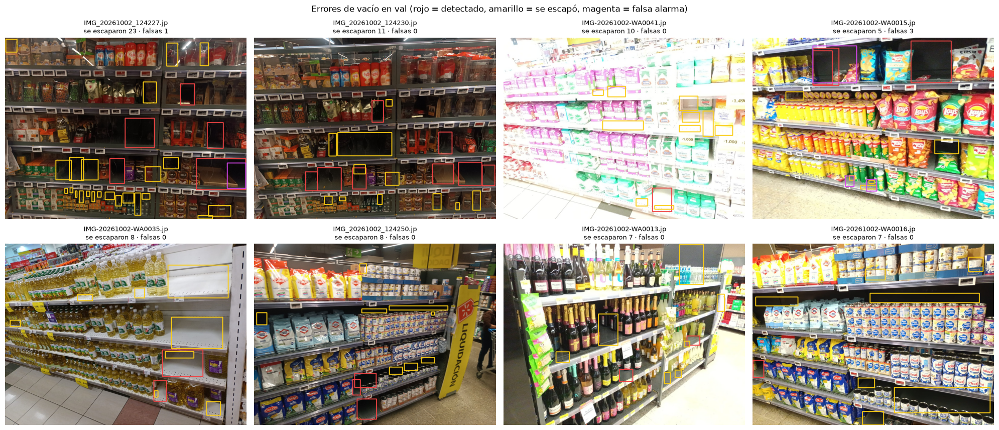

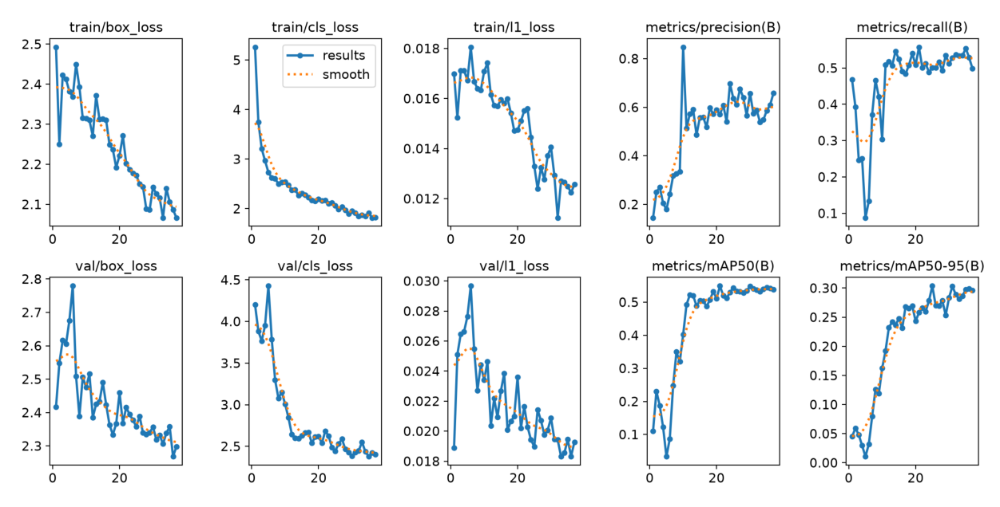

In [23]:
# [Celda 22] Evaluación: ¿encuentra cada vacío?
metricas = modelo.val(data=str(DATA_YAML), split="val", imgsz=CFG["imgsz"], batch=CFG["batch"],
                      device=DEVICE, workers=CFG["workers"], plots=False, verbose=False)
tabla_metricas = pd.DataFrame([{"clase": CLASES[int(c)], "precision": metricas.box.p[i], "recall": metricas.box.r[i],
                                "mAP50": metricas.box.ap50[i], "mAP50-95": metricas.box.ap[i]}
                               for i, c in enumerate(metricas.box.ap_class_index)]).round(3)
print(tabla_metricas.to_string(index=False))

# Vacío por vacío (IoU >= 0.3 cuenta como encontrado)
ID_VACIO = CLASES.index("vacio")
errores_vacio, tp, fp, fn = [], 0, 0, 0
for f in [f for f in fotos if f["split"] == "val" and ruta_revisada(f).exists()]:
    reales = [c["b"] for c in leer_revisada(f) if c["c"] == ID_VACIO]
    res = modelo.predict(str(f["ruta"]), imgsz=CFG["imgsz"], conf=CFG["conf"], device=DEVICE, verbose=False)[0]
    pred = [b for c, b, s in a_lista(res) if c == ID_VACIO]
    usados, aciertos = set(), 0
    for r in reales:
        mejor = max(range(len(pred)), key=lambda j: iou(r, pred[j]), default=None)
        if mejor is not None and mejor not in usados and iou(r, pred[mejor]) >= 0.3:
            usados.add(mejor); aciertos += 1
    perdidos = [r for r in reales if all(iou(r, p) < 0.3 for p in pred)]
    falsos = [p for j, p in enumerate(pred) if j not in usados and all(iou(p, r) < 0.3 for r in reales)]
    tp, fp, fn = tp + aciertos, fp + len(falsos), fn + len(perdidos)
    errores_vacio.append({"foto": f, "perdidos": perdidos, "falsos": falsos, "pred": pred})

if errores_vacio:
    print(f"\nVacíos en val: {tp + fn} reales | encontrados {tp} | se escaparon {fn} | falsas alarmas {fp}")
    print(f"Recall vacío: {tp / max(1, tp + fn):.2f} | Precisión vacío: {tp / max(1, tp + fp):.2f}")
    peores = sorted(errores_vacio, key=lambda e: -(len(e["perdidos"]) + len(e["falsos"])))[:8]
    fig, axes = plt.subplots(2, 4, figsize=(20, 9))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, e in zip(axes.ravel(), peores):
        img = cv2.cvtColor(cv2.imread(str(e["foto"]["ruta"])), cv2.COLOR_BGR2RGB)
        for b in e["pred"]:
            cv2.rectangle(img, tuple(map(int, b[:2])), tuple(map(int, b[2:])), COLORES_RGB[ID_VACIO], 3)
        for b in e["perdidos"]:
            cv2.rectangle(img, tuple(map(int, b[:2])), tuple(map(int, b[2:])), (250, 204, 21), 4)
        for b in e["falsos"]:
            cv2.rectangle(img, tuple(map(int, b[:2])), tuple(map(int, b[2:])), (217, 70, 239), 4)
        ax.imshow(img)
        ax.set_title(f"{e['foto']['nombre'][:22]}\nse escaparon {len(e['perdidos'])} · falsas {len(e['falsos'])}", fontsize=9)
    plt.suptitle("Errores de vacío en val (rojo = detectado, amarillo = se escapó, magenta = falsa alarma)")
    plt.tight_layout(); plt.show(); plt.close(fig)
else:
    print("\n⚠️  No hay fotos de val revisadas: revisa val en la celda 16 para medir vacíos de verdad.")

curvas = RUNS_DIR / "final" / "results.png"
if curvas.exists():
    plt.figure(figsize=(16, 8)); plt.imshow(Image.open(curvas)); plt.axis("off"); plt.show()

### Celda 23 · Análisis de quiebres por góndola

- **Qué hace:** Para cada foto de val: detecta góndolas y vacíos y calcula, **por góndola**, `% vacío = área de vacíos / área de la góndola`. Marca alerta si supera `CFG['alerta_vacio']`. Guarda las imágenes y `reporte_vacios.csv` en `stockeye_v4/resultados/`.
- **Qué necesita:** Celda 21.
- **Qué deja listo:** Función `analizar_foto(ruta)` y el DataFrame `reporte`.
- **Tiempo y recursos:** ~1 s por foto (`MOSAICO_INFERENCIA = True` ve mejor vacíos pequeños en fotos lejanas, ~4× más lento).
- **Qué revisar:** Las góndolas con alerta y que los vacíos rojos correspondan a huecos reales.

                     foto  gondola  vacios  pct_vacio  alerta
  IMG-20261002-WA0015.jpg        1       6       13.4    True
  IMG-20261002-WA0040.jpg        1      10        9.6   False
  IMG_20261002_124227.jpg        1       6        9.4   False
  IMG_20261002_124230.jpg        1       8        7.0   False
  IMG_20261002_124248.jpg        1       6        6.9   False
  IMG-20261002-WA0039.jpg        1       3        6.0   False
  IMG_20261002_124252.jpg        1       3        5.7   False
  IMG-20261002-WA0034.jpg        1       3        4.5   False
  IMG_20261002_124153.jpg        1       5        4.2   False
  IMG-20261002-WA0042.jpg        1       4        4.1   False
  IMG-20261002-WA0035.jpg        1       2        3.7   False
  IMG_20261002_124313.jpg        1       1        3.4   False
  IMG_20261002_124240.jpg        1       2        3.2   False
  IMG_20261002_124250.jpg        1       3        2.3   False
  IMG-20261002-WA0037.jpg        1       4        2.1   False
  IMG-20

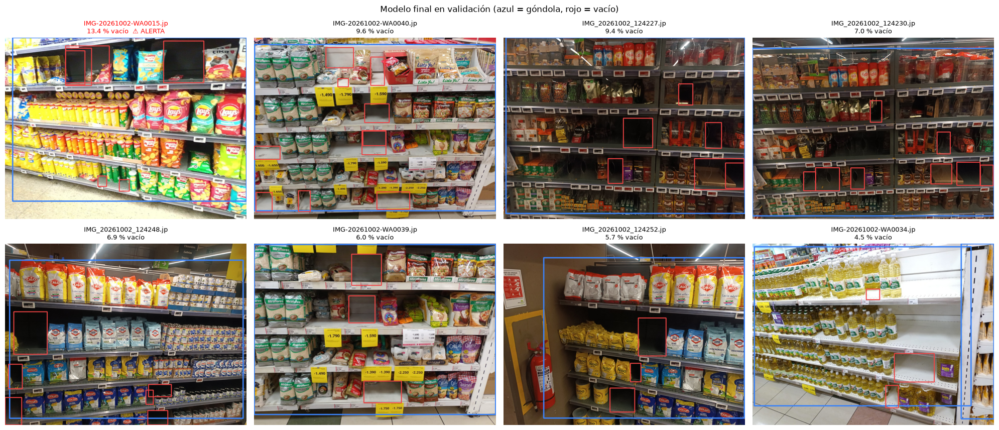

In [24]:
# [Celda 23] Análisis de quiebres por góndola
MOSAICO_INFERENCIA = False

def predecir_final(img_bgr, conf):
    # Foto completa; opcionalmente también mosaico 2x2 para vacíos pequeños
    res = modelo.predict(img_bgr, imgsz=CFG["imgsz"], conf=conf, device=DEVICE, verbose=False)[0]
    dets = {k: [] for k in CLASES}
    for c, b, s in a_lista(res):
        dets[CLASES[c]].append({"box": b, "score": s})
    if MOSAICO_INFERENCIA:
        H, W = img_bgr.shape[:2]
        for (x1, y1, x2, y2) in generar_mosaicos(W, H, 2, 0.25):
            r = modelo.predict(img_bgr[y1:y2, x1:x2], imgsz=CFG["imgsz"], conf=conf, device=DEVICE, verbose=False)[0]
            for c, b, s in a_lista(r, x1, y1):
                if CLASES[c] != "gondola":
                    dets[CLASES[c]].append({"box": b, "score": s})
        dets = {k: nms(v) for k, v in dets.items()}
    return dets

def analizar_foto(ruta, conf=None, guardar=True):
    vigilar_temperatura()
    ruta = Path(ruta)
    img = cv2.imread(str(ruta))
    H, W = img.shape[:2]
    d = predecir_final(img, conf or CFG["conf"])
    gondolas = d["gondola"] or [{"box": [0, 0, W, H], "score": 0.0}]   # sin góndola: toda la foto
    filas = []
    for gi, g in enumerate(gondolas):
        vacs = [v for v in d["vacio"] if centro_dentro(v["box"], g["box"])]
        a_v = sum(interseccion(v["box"], g["box"]) for v in vacs)       # área de vacíos dentro de la góndola
        pct = a_v / max(1.0, area(g["box"]))
        filas.append({"foto": ruta.name, "gondola": gi + 1, "vacios": len(vacs),
                      "pct_vacio": round(100 * pct, 1), "alerta": pct > CFG["alerta_vacio"]})
    cajas = [(CLASES.index(k), c["box"], False) for k in CLASES for c in d[k]]
    dibujo = dibujar_cajas(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cajas)
    if guardar:
        Image.fromarray(dibujo).save(RESULT_DIR / ruta.name)
    return filas, dibujo

resultados = {f["nombre"]: analizar_foto(f["ruta"]) for f in fotos if f["split"] == "val"}
reporte = pd.DataFrame([fila for filas, _ in resultados.values() for fila in filas])
reporte.to_csv(RESULT_DIR / "reporte_vacios.csv", index=False)
print(reporte.sort_values("pct_vacio", ascending=False).to_string(index=False))
print(f"\nGóndolas con alerta: {int(reporte.alerta.sum())} de {len(reporte)}")

top = reporte.groupby("foto").pct_vacio.max().sort_values(ascending=False).index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax in axes.ravel():
    ax.axis("off")
for ax, nombre in zip(axes.ravel(), top):
    filas, dibujo = resultados[nombre]
    peor = max(filas, key=lambda r: r["pct_vacio"])
    ax.imshow(dibujo)
    ax.set_title(f"{nombre[:22]}\n{peor['pct_vacio']} % vacío" + ("  ⚠ ALERTA" if peor["alerta"] else ""),
                 fontsize=9, color="red" if peor["alerta"] else "black")
plt.suptitle("Modelo final en validación (azul = góndola, rojo = vacío)")
plt.tight_layout(); plt.show(); plt.close(fig)

### Celda 24 · Probar con una foto propia

- **Qué hace:** Analiza cualquier foto (JPG/PNG) con el modelo final.
- **Qué necesita:** Celda 23.
- **Qué deja listo:** Una figura con el resultado por góndola.
- **Tiempo y recursos:** ~1 s.
- **Qué revisar:** Cambia `FOTO_NUEVA` por la ruta de tu foto.

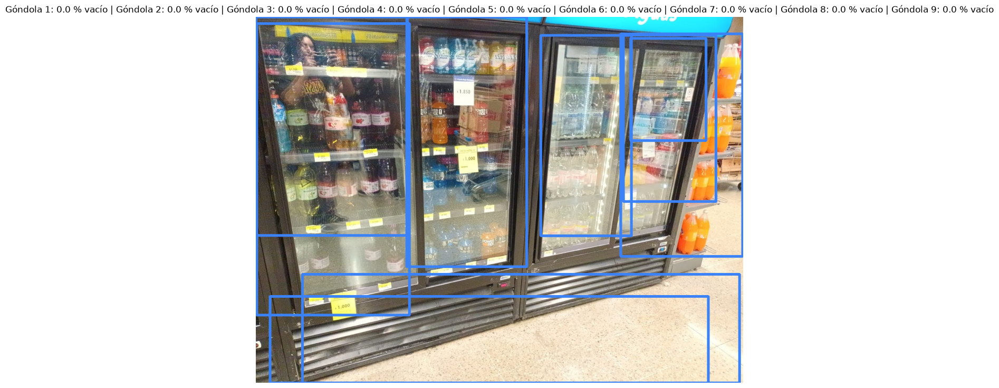

In [25]:
# [Celda 24] Probar con una foto propia
FOTO_NUEVA = fotos[0]["ruta"]      # <- cambia por ej. a Path("mi_gondola.jpg")

filas, dibujo = analizar_foto(FOTO_NUEVA)
plt.figure(figsize=(12, 9)); plt.imshow(dibujo); plt.axis("off")
plt.title(" | ".join(f"Góndola {r['gondola']}: {r['pct_vacio']} % vacío" + (" ⚠" if r["alerta"] else "") for r in filas))
plt.show()

### Celda 25 · (Opcional) Exportar a OpenVINO

- **Qué hace:** Exporta el modelo final a OpenVINO, que acelera la inferencia 2–3× en CPU Intel/AMD.
- **Qué necesita:** Celda 21.
- **Qué deja listo:** Carpeta `stockeye_v4_best_openvino_model/` (se usa con `YOLO(ruta)` igual que el `.pt`).
- **Tiempo y recursos:** ~1 min.
- **Qué revisar:** Pon `EXPORTAR = True` para ejecutarla.

In [26]:
# [Celda 25] (Opcional) Exportar a OpenVINO
EXPORTAR = False

if EXPORTAR:
    print("Exportado en:", YOLO(str(MODELO_FINAL)).export(format="openvino", imgsz=CFG["imgsz"]))
else:
    print("Exportación omitida (EXPORTAR = False).")

Exportación omitida (EXPORTAR = False).


## Archivos generados

| Ruta | Contenido |
|---|---|
| `stockeye_v4/fotos/` | fotos normalizadas (enlazadas desde v3) |
| `stockeye_v4/pesos/` | detectores (Colab + Hugging Face), revisados con `escanear_pt` |
| `stockeye_v4/cache/<fuente>/` | detecciones crudas por fuente (borrar una carpeta = recalcular esa fuente) |
| `stockeye_v4/etiquetas_revisadas/` | **tus etiquetas** (YOLO `.txt`): el activo más valioso del proyecto |
| `stockeye_v4/dataset/` | dataset YOLO (se regenera en cada ronda) |
| `stockeye_v4/runs/maestro`, `runs/final` | entrenamientos, curvas y pesos |
| `stockeye_v4/stockeye_v4_best.pt` | **modelo final** |
| `stockeye_v4/resultados/` | fotos analizadas y `reporte_vacios.csv` |